# Backtest — Reversión a la media anclada al VWAP sobre Binance USDⓈ-M Perpetuals

**Estrategia.** Fade de ruptura Donchian con barra de confirmación, pero con dos cambios
respecto del sistema validado en `MeanReversion_Binance_Perp.ipynb`:

| | Sistema clásico | **Este** |
|---|---|---|
| Detección | ruptura del canal Donchian de 20 barras | *igual* |
| **Filtro de entrada** | ninguno | **el extremo de la ruptura debe estar a ≥ 2N del VWAP** |
| Confirmación | el cierre de `t+1` vuelve dentro del canal | *igual* |
| Entrada | open de `t+2`, lado invertido | *igual* |
| Stop | 1N desde el último fill | **2N** |
| **Objetivo** | centro del canal `(ent_hi+ent_lo)/2` | **`take_n`·N desde la entrada** (desacoplado del canal) |
| Barrera temporal | 10 barras | **`max_hold_bars` del motor** (hoy 20; §8.2 lo barre) |
| Papel del VWAP | — | **filtro de entrada y compuerta de la escalera**, no objetivo |
| **Stop / objetivo fuera de sesión** | — | **órdenes en reposo 24/7**: se evalúan sobre el camino completo, también de noche |
| Regla de drawdown | tramos de 10 % desde el capital inicial | **tramos de 10 % desde el máximo del saldo** |

> **Corrección importante (versión actual).** Las versiones anteriores de este cuaderno
> filtraban la serie a la sesión pero mantenían posiciones abiertas de noche **sin ver** qué
> pasaba fuera de ella: un stop tocado de madrugada que volvía antes de la apertura no existía
> para el motor. Medido: el 78 % de las operaciones cruza al menos una noche, y el 34 % toca
> el stop fuera de sesión antes de que el motor lo vea. Esa ceguera producía **todo** el edge
> que se había presentado —la cartera pasaba de 100k a 5,7M—. Con los stops evaluados de noche
> como órdenes reales, el sistema pierde. Los resultados de abajo son los corregidos.

**Por qué el objetivo ya no es el centro del canal.** Medido: con el objetivo anclado al canal,
el payoff cae casi exactamente como `1/stop_n` (3,82 con stop 0,5N → 1,13 con stop 2N) mientras
el acierto **satura en ~48 %**. El motivo es que el objetivo no se mueve cuando se ensancha el
stop: ensanchar regala recompensa de forma proporcional a cambio de aciertos con rendimientos
decrecientes, y la esperanza cae de forma monótona. Stop y objetivo tienen que moverse juntos, y
para eso el objetivo debe medirse en N desde la entrada, no en el canal.

**Qué es y qué no es el VWAP aquí.** Con el objetivo desacoplado, el VWAP **ya no es la media a
la que se revierte**. Le quedan dos trabajos, ambos reales: decidir qué ruptura se opera (el
filtro de ≥ 2N de estiramiento) y cerrar la escalera de adds cuando el precio lo alcanza
(`add_until_mid`). Conviene ser explícito porque cambia la tesis: esto ya no es "revertir al
VWAP", es "desvanecer una ruptura que llegó estirada respecto del VWAP".

**Por qué el filtro de 2N.** Exigir que la ruptura llegue estirada ≥ 2N del VWAP selecciona las
excursiones que de verdad se alejaron del precio negociado, en vez de operar toda ruptura del
canal. §5 mide cuánto corta y §7 barre el umbral.

**Universo.** Piloto de cuatro cripto (BTC, ETH, SOL, LINK) **más QQQ**, el perpetuo sobre el
Nasdaq-100 que Binance lista como `QQQUSDT`. Todo el proceso está escrito sobre una lista:
añadir un token es editar `PILOT`.

**Ventana.** Desde 2022-01-01, **restringida a la sesión regular (09:30–16:15 hora de Nueva
York, días hábiles)** para todos los símbolos, cripto incluidas. **No se recorta la ventana** al
símbolo más joven: QQQ listó el 2026-04-06 y sencillamente no existe —ni puede emitir señal—
antes de su primera barra.

**El orden del filtro no es un detalle.** Se filtran las barras **primero** y se calculan N, el
canal y el VWAP **sobre la serie ya filtrada**. Calcularlos en 24/7 y quedarse después con las
señales de la sesión dejaría las barras de madrugada y fin de semana dentro del indicador:
medido sobre BTCUSDT, el semiancho del canal en N cae de 2,60 a 2,02 al pasar de sesión a 24/7.

**Pero filtrar las señales no filtra el riesgo.** La cripto no cierra: una posición abierta a
las 16:00 sigue expuesta toda la noche. Por eso las órdenes de salida se evalúan sobre el camino
24/7 completo (ver la corrección de arriba).


### Sesgos declarados antes de empezar

| Sesgo | Control en este cuaderno |
|---|---|
| Look-ahead | §4 trunca la serie en 30 puntos y comprueba que N, el canal y **el VWAP** no cambian |
| Optimización | el umbral 2N se **barre** en §7; `n_trials` del DSR usa el tamaño real de la rejilla |
| Elección del ancla | el VWAP con ventana móvil de una jornada es una **decisión previa**, no el ganador de una búsqueda; §7 muestra también el modo anclado a la sesión |
| Elección del régimen | la sesión regular **no** se eligió mirando este resultado: sale de la medición del cuaderno anterior (§12.6) y de la descomposición de coste por R; aun así, §7 y §9 la someten a barrido y a fuera de muestra |
| Supervivencia | §11 lista la fecha de listado de cada símbolo; QQQ se reporta aparte por muestra corta |
| Costes | comisión taker + deslizamiento + **funding real** por símbolo, con sensibilidad en §11 |
| Muestra corta | QQQ tiene 0,44 años: es una **sonda, no evidencia**, y así se reporta en cada tabla |


## §1. Setup y configuración


In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 50)

plt.rcParams.update({
    "figure.figsize": (14, 6), "axes.grid": True, "grid.alpha": 0.25,
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
})

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)

from qsCrypto.config.universe import load_universe
from qsCrypto.backtest.binance_data import (
    fetch_pilot_universe, restrict_to_session, RTH_TZ, RTH_START, RTH_END,
)
from qsCrypto.backtest.engine import (
    BacktestParams, run_backtest, run_portfolio_backtest,
)
from qsCrypto.strategy.strategy import (
    compute_n, compute_vwap, breakout_stretch, is_flat_bar, vwap_fade_policy,
)
from qsCrypto.backtest.skill_stats.bias_audit import (
    assert_no_lookahead, pnl_concentration, effective_bets,
    cost_sensitivity, mc_bootstrap_trades, equity_metrics,
)
from qsCrypto.backtest.skill_stats.purged_cv import walk_forward_folds
from qsCrypto.backtest.skill_stats.stats_tests import (
    deflated_sharpe_ratio, fold_ttest, pbo_cscv,
)

print(f"ROOT : {ROOT}")
print("Setup OK")


ROOT : /Users/diegoochoa/Projects/Intraday_MR_BTC
Setup OK


### §1.1 Parámetros

El riesgo por operación (1 %), la escalera de 1/2N y la regla de drawdown vienen del sistema ya
validado. Lo que sí cambia respecto de él, y conviene tenerlo delante al leer los resultados:

* **`stop_n = 2`** en vez de 1N.
* **Sin objetivo efectivo: `tp_mode = "take_n"`, `take_n = 50`**. Un objetivo a 50N no se alcanza
  en la práctica; se deja así, "apagado", por la recomendación de §8.2: `take_n` y
  `max_hold_bars` son dos palancas para el mismo efecto (cuánto se deja correr al ganador), y
  buscar sobre las dos duplica la búsqueda sin añadir información. Se valida solo la barrera
  temporal. (Con `tp_mode="mid_channel"` el parámetro `take_n` ni siquiera se lee.)
* **`max_hold_bars`** se lee del motor (hoy 20 barras, ~1,4 sesiones).
* **`max_units = 6`**.

`TAKE_N` se fija **aquí** y prevalece sobre el `take_n` del dataclass: si se cambia en
`engine.py` sin cambiarlo aquí, este cuaderno no lo ve.

Con el objetivo apagado, las salidas son tres: el **stop de 2N** (que la escalera de adds
arrastra a favor), la **barrera temporal** y, testimonialmente, el objetivo. §8.3 mide cómo se
comporta la excursión adversa respecto de ese stop.


In [2]:
SESSION_ONLY = True           # restringir a la sesión regular antes de todo
PILOT    = ["BTCUSDT", "ETHUSDT", "SOLUSDT", "LINKUSDT", "QQQUSDT"]
FLAGSHIP = "BTCUSDT"          # referencia para WFO, DSR/PBO y Monte Carlo
INTERVAL = "30m"
START    = "2022-01-01"
END      = "2026-09-13 00:00:00"   # ancla explícita: la muestra no cambia según el día

BARS_PER_SESSION = 14                # 09:30-16:15 en barras de 30 min

# Objetivo APAGADO: medido en N desde la entrada y puesto tan lejos (50N) que
# no se toca. §8.2 mostró que take_n y max_hold_bars hacen lo mismo; se deja
# una sola palanca —la barrera temporal— y es la única que se valida en §9.
# Cableado aquí y no heredado del dataclass: tiene que quedar a la vista.
TP_MODE = "take_n"
TAKE_N  = 50.0
WFO_HOLDS = (10, 15, 20, 30, 45)     # la única rejilla del walk-forward

# Órdenes en reposo 24/7: las señales salen de la sesión, pero el stop (y el
# objetivo) están puestos en el exchange día y noche. El motor los evalúa sobre
# el camino 24/7 completo entre dos barras de sesión. Sin esto el backtest es
# ciego a todo lo que pasa de noche y en fin de semana.
RESTING_24_7 = True
# Regla de drawdown medida desde el MÁXIMO del saldo, no desde el capital
# inicial: la histórica deja de actuar en cuanto la cuenta supera equity0.
DD_FROM_PEAK = True

BASELINE = BacktestParams(**{**BacktestParams().__dict__,
                             "tp_mode": TP_MODE, "take_n": TAKE_N,
                             "dd_from_peak": DD_FROM_PEAK})
# El sistema original, con el objetivo en el centro del canal: es el contraste.
CHANNEL = BacktestParams(**{**BacktestParams().__dict__,
                            "tp_mode": "mid_channel", "dd_from_peak": DD_FROM_PEAK})
MIN_RANGE_N = 2.0                    # el filtro: >= 2N del extremo al VWAP
VWAP_MODE   = "rolling"
# Una jornada de mercado, en barras de la serie que se va a usar.
VWAP_BARS   = BARS_PER_SESSION if SESSION_ONLY else 48

POLICY = vwap_fade_policy(min_range_n=MIN_RANGE_N, vwap_mode=VWAP_MODE,
                          vwap_bars=VWAP_BARS)

print(BASELINE)
print(f"\nObjetivo     : apagado ({TP_MODE} = {TAKE_N:.0f}N, inalcanzable en la práctica)")
print(f"Stop         : {BASELINE.stop_n}N desde el último fill (1R = {BASELINE.stop_n}N)")
print(f"Barrera temp.: {BASELINE.max_hold_bars} barras "
      f"({BASELINE.max_hold_bars/BARS_PER_SESSION:.1f} sesiones)")
print(f"Política VWAP: umbral={MIN_RANGE_N}N  modo={VWAP_MODE}  ventana={VWAP_BARS} barras")
print(f"Piloto       : {PILOT}")


BacktestParams(entry_bars=20, atr_period=20, stop_n=2.0, add_n=0.5, max_units=6, max_hold_bars=20, tp_mode='take_n', take_n=50.0, risk_per_trade=0.01, equity0=10000.0, fee_bps=0.0002, slip_bps=0.0001, max_gross_lev=10.0, use_dd_rule=True, allow_short=True, require_confirmation=True, mae_stop_n=None, dd_from_peak=True, flat_at_session_end=False)

Objetivo     : apagado (take_n = 50N, inalcanzable en la práctica)
Stop         : 2.0N desde el último fill (1R = 2.0N)
Barrera temp.: 20 barras (1.4 sesiones)
Política VWAP: umbral=2.0N  modo=rolling  ventana=14 barras
Piloto       : ['BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'LINKUSDT', 'QQQUSDT']


### §1.2 Costes

Un perpetuo cobra comisión de nocional en cada lado **y** liquida *funding* cada 8 h. El
funding es real, descargado por símbolo, no un supuesto: en una estrategia que aguanta una
mediana de pocas barras pesa poco, pero no es cero y se contabiliza.


In [3]:
print(f"  fee_bps (taker, un lado) : {BASELINE.fee_bps*1e4:.2f} pb")
print(f"  slip_bps (un lado)       : {BASELINE.slip_bps*1e4:.2f} pb")
print(f"  round-trip               : {(BASELINE.fee_bps+BASELINE.slip_bps)*2*1e4:.2f} pb de nocional")
print(f"  funding                  : histórico REAL por símbolo, cada 8 h")
print(f"  max_gross_lev            : {BASELINE.max_gross_lev}x")


  fee_bps (taker, un lado) : 2.00 pb
  slip_bps (un lado)       : 1.00 pb
  round-trip               : 6.00 pb de nocional
  funding                  : histórico REAL por símbolo, cada 8 h
  max_gross_lev            : 10.0x


## §2. Universo y grupos de correlación

Las cripto y sus grupos salen del YAML del piloto. **QQQ se declara aquí**, porque no está en
el universo Coinbase50 que lee `load_universe`, y va en **su propio grupo**: un índice de renta
variable no es un layer-1 alternativo, y meterlo en el mismo saco haría que los topes de
correlación lo trataran como un gemelo de SOL.


In [4]:
UNIVERSE = load_universe()
YAML_GROUPS = {s: UNIVERSE.corr_groups[s] for s in UNIVERSE.symbols}

EXTRA_GROUPS = {"QQQUSDT": "equity_index"}
CORR_GROUPS = {s: YAML_GROUPS.get(s, EXTRA_GROUPS.get(s, "otros")) for s in PILOT}

print(f"Universo YAML : {UNIVERSE.universe_name}")
for s in PILOT:
    print(f"  {s:<10} -> grupo {CORR_GROUPS[s]}")
assert FLAGSHIP in PILOT


Universo YAML : coinbase50_pilot_v1
  BTCUSDT    -> grupo layer1_major
  ETHUSDT    -> grupo layer1_major
  SOLUSDT    -> grupo layer1_alt
  LINKUSDT   -> grupo defi
  QQQUSDT    -> grupo equity_index


## §3. Datos — reales, cacheados en disco

`GET /fapi/v1/klines` (30 m) y `GET /fapi/v1/fundingRate`, cacheados en
`data_cache/binance/`. La vela en formación se descarta siempre.

**Aquí, y solo aquí, se aplica el filtro de sesión.** A partir de esta celda `DATA` ya no
contiene madrugadas ni fines de semana, así que todo lo que se calcule después —N, canal, VWAP,
señales— nace de la serie filtrada. La ventana va en hora de Nueva York, de modo que el horario
de verano queda resuelto solo.

**Las órdenes en reposo tampoco se filtran.** El stop y el objetivo están puestos en el
exchange las 24 horas; el motor recorre las velas 24/7 que hay entre dos velas de sesión
(`PATHS`) y los ejecuta donde se toquen, con motivo de salida `stop_fuera` / `target_fuera`.
Los adds y la barrera temporal sí son de sesión: son decisiones del sistema, no órdenes puestas.

**El funding NO se filtra.** Una posición abierta el viernes a las 15:45 sigue viva —y sigue
pagando funding cada 8 h— durante el fin de semana, aunque el sistema no la mire hasta el lunes.
Recortar los pagos a la sesión regalaría un coste real.

**QQQ arranca tarde y eso se respeta.** La tabla muestra la primera barra real de cada símbolo:
recortar la muestra de BTC a los 160 días de QQQ tiraría cuatro años y medio de historia, e
inventar barras anteriores a su listado sería falsificar el backtest.


In [5]:
DATA_24_7, FUNDING = fetch_pilot_universe(PILOT, interval=INTERVAL, start=START, end=END)

if SESSION_ONLY:
    DATA = {s: restrict_to_session(d) for s, d in DATA_24_7.items()}
    print(f"Sesión regular {RTH_START}-{RTH_END} {RTH_TZ}, días hábiles.")
    for s in PILOT:
        print(f"  {s:<10} {len(DATA_24_7[s]):>6} barras 24/7 -> {len(DATA[s]):>6} de sesión "
              f"({100*len(DATA[s])/len(DATA_24_7[s]):.1f}%)")
else:
    DATA = DATA_24_7
    print("Sin filtro de sesión: historia 24/7 completa.")

# Camino sobre el que se evalúan las órdenes en reposo. Siempre la serie 24/7
# COMPLETA del símbolo: el motor solo mira las velas que caen ENTRE dos barras
# de la serie operada, así que sirve igual para una ventana del walk-forward.
PATHS = DATA_24_7 if (SESSION_ONLY and RESTING_24_7) else {}
print(f"\nStops en reposo 24/7: {'sí' if PATHS else 'no'}   "
      f"Regla de drawdown desde el máximo: {'sí' if DD_FROM_PEAK else 'no'}")

# Prueba de que el filtro se aplicó ANTES que cualquier indicador: en la serie
# que se va a usar no queda ni una barra fuera de la sesión.
if SESSION_ONLY:
    for s in PILOT:
        assert DATA[s].equals(restrict_to_session(DATA[s])), s
    print("\n✓ Indicadores y señales se calcularán sobre la serie ya filtrada")

# Anualización: `equity_metrics` escala la desviación de los retornos POR BARRA,
# así que `freq` son barras al año, no días. El cuaderno de referencia pasaba 365
# con barras de 30 min, lo que infravalora la volatilidad y dispara el Sharpe en
# valor absoluto; sus Sharpe y los de aquí NO son comparables entre sí.
_ref = DATA[FLAGSHIP]
FREQ = int(round(len(_ref) / ((_ref.index[-1] - _ref.index[0]).days / 365.25)))
print(f"\nFREQ (barras/año, medido sobre {FLAGSHIP}): {FREQ}")

INV = pd.DataFrame([
    {"símbolo": s, "primera barra": DATA[s].index[0], "última": DATA[s].index[-1],
     "barras": len(DATA[s]),
     "años": round((DATA[s].index[-1] - DATA[s].index[0]).days / 365.25, 2),
     "funding": len(FUNDING[s]),
     "barras planas %": round(100 * np.mean([
         is_flat_bar(h, l, v) for h, l, v in
         zip(DATA[s]["high"], DATA[s]["low"], DATA[s]["volume"])]), 3),
     "vol. cero %": round(100 * (DATA[s]["volume"] <= 0).mean(), 3)}
    for s in PILOT])
display(INV)

# "Tardío" es respecto al arranque común del piloto, no respecto a START: tras
# filtrar la sesión, la primera barra de todos cae en el primer día hábil.
_first = min(DATA[s].index[0] for s in PILOT)
LATE = [s for s in PILOT if (DATA[s].index[0] - _first).days > 30]
for s in LATE:
    print(f"⚠ {s}: empieza el {DATA[s].index[0]} — "
          f"{round((DATA[s].index[-1]-DATA[s].index[0]).days/365.25, 2)} años de muestra. "
          f"Sonda, no evidencia.")
assert all(len(DATA[s]) > 200 for s in PILOT)


Sesión regular 09:30-16:15 America/New_York, días hábiles.
  BTCUSDT     82369 barras 24/7 ->  17150 de sesión (20.8%)
  ETHUSDT     82369 barras 24/7 ->  17150 de sesión (20.8%)
  SOLUSDT     82369 barras 24/7 ->  17150 de sesión (20.8%)
  LINKUSDT    82369 barras 24/7 ->  17150 de sesión (20.8%)
  QQQUSDT      7654 barras 24/7 ->   1610 de sesión (21.0%)

Stops en reposo 24/7: sí   Regla de drawdown desde el máximo: sí

✓ Indicadores y señales se calcularán sobre la serie ya filtrada

FREQ (barras/año, medido sobre BTCUSDT): 3659


,símbolo,primera barra,última,barras,años,funding,barras planas %,vol. cero %
0,BTCUSDT,2022-01-03 14:30:00,2026-09-11 20:00:00,17150,4.69,5148,0.0,0.0
1,ETHUSDT,2022-01-03 14:30:00,2026-09-11 20:00:00,17150,4.69,5148,0.0,0.0
2,SOLUSDT,2022-01-03 14:30:00,2026-09-11 20:00:00,17150,4.69,5223,0.0,0.0
3,LINKUSDT,2022-01-03 14:30:00,2026-09-11 20:00:00,17150,4.69,5148,0.0,0.0
4,QQQUSDT,2026-04-06 13:30:00,2026-09-11 20:00:00,1610,0.43,497,0.0,0.0


⚠ QQQUSDT: empieza el 2026-04-06 13:30:00 — 0.43 años de muestra. Sonda, no evidencia.


## §4. Indicadores y test de look-ahead

Los tres indicadores salen del **módulo de la estrategia viva** (`qsCrypto.strategy.strategy`),
no de una copia del notebook: es la única garantía de que el backtest mide lo que el sistema
opera.

El VWAP es la superficie de look-ahead genuinamente nueva, así que se audita igual que N y el
canal: se trunca la serie en 30 puntos y se comprueba que el valor en `t` no cambia. **La barra
en curso sí entra en su propio VWAP** —a diferencia del canal Donchian, que se rompería contra
sí mismo— porque es un precio medio ya conocido al cierre de la barra, que es el instante en
que se decide.


In [6]:
df0 = DATA[FLAGSHIP]

def n_feature(d):
    return pd.Series(compute_n(d["high"].to_numpy(), d["low"].to_numpy(),
                               d["close"].to_numpy(), period=BASELINE.atr_period),
                     index=d.index)

def channel_feature(d):
    return d["high"].rolling(BASELINE.entry_bars).max().shift(1)

def vwap_feature(d):
    return pd.Series(compute_vwap(
        d["high"].to_numpy(float), d["low"].to_numpy(float),
        d["close"].to_numpy(float), d["volume"].to_numpy(float),
        mode=VWAP_MODE, bars=VWAP_BARS, index=d.index), index=d.index)

res_n  = assert_no_lookahead(n_feature, df0, n_checks=30)
res_ch = assert_no_lookahead(channel_feature, df0, n_checks=30)
res_vw = assert_no_lookahead(vwap_feature, df0, n_checks=30)
print(f"  compute_n (N)   : {res_n.ok.sum()}/{len(res_n)} truncamientos pasan")
print(f"  canal Donchian  : {res_ch.ok.sum()}/{len(res_ch)} truncamientos pasan")
print(f"  VWAP ({VWAP_MODE}) : {res_vw.ok.sum()}/{len(res_vw)} truncamientos pasan")
LOOKAHEAD_OK = bool(res_n.ok.all() and res_ch.ok.all() and res_vw.ok.all())
assert LOOKAHEAD_OK, "LOOK-AHEAD DETECTADO — no seguir sin arreglarlo"
print("\n✓ Sin look-ahead: la feature en `t` no cambia al truncar el histórico ahí")


  compute_n (N)   : 30/30 truncamientos pasan
  canal Donchian  : 30/30 truncamientos pasan
  VWAP (rolling) : 30/30 truncamientos pasan

✓ Sin look-ahead: la feature en `t` no cambia al truncar el histórico ahí


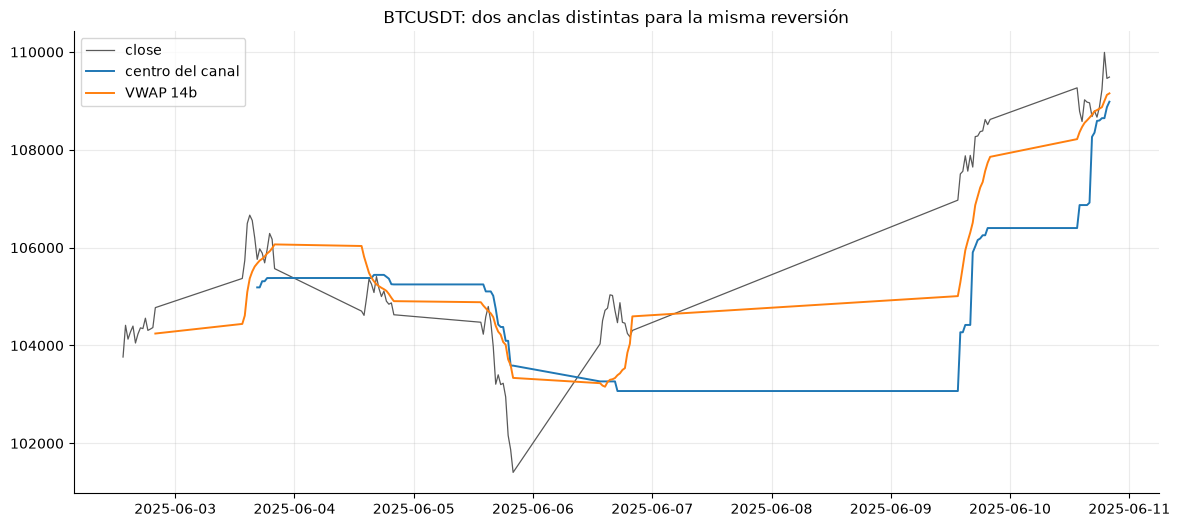

In [7]:
# El VWAP frente al centro del canal, sobre una ventana corta del bandera.
w = df0.loc["2025-06-01":"2025-06-10"]
mid = ((w["high"].rolling(BASELINE.entry_bars).max().shift(1)
        + w["low"].rolling(BASELINE.entry_bars).min().shift(1)) / 2)
fig, ax = plt.subplots()
ax.plot(w.index, w["close"], lw=0.9, color="0.35", label="close")
ax.plot(w.index, mid, lw=1.4, label="centro del canal")
ax.plot(w.index, vwap_feature(w), lw=1.4, label=f"VWAP {VWAP_BARS}b")
ax.set_title(f"{FLAGSHIP}: dos anclas distintas para la misma reversión")
ax.legend(); plt.show()


## §5. ¿Qué corta exactamente el umbral de 2N?

Antes de mirar un solo resultado de P&L: la distribución del **estiramiento** de cada ruptura
detectada, medido en N desde el extremo hasta el VWAP. Si la mayoría de las rupturas ya
estuvieran por encima de 2N, el filtro no filtraría nada y el ejercicio sobraría.


,símbolo,rupturas,p50,p75,p90,% ≥ 2.0N
0,BTCUSDT,3271,2.49,3.22,4.07,73.6%
1,ETHUSDT,3118,2.52,3.25,4.21,75.7%
2,SOLUSDT,3302,2.51,3.28,4.13,73.7%
3,LINKUSDT,3518,2.47,3.29,4.33,71.1%
4,QQQUSDT,400,2.36,2.98,3.50,67.8%


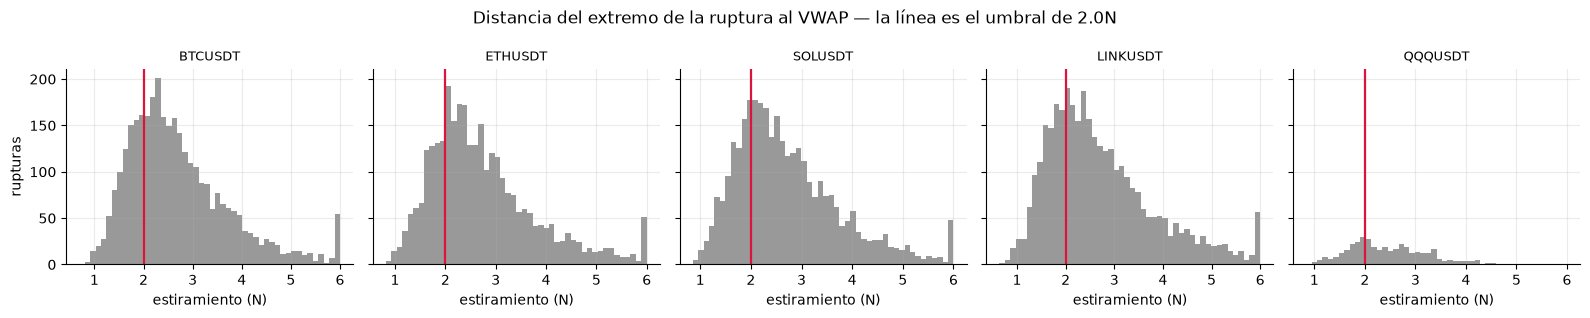

In [8]:
# Estiramiento (en N) de TODA ruptura del canal, la mire o no la estrategia.
def breakout_stretches(d, params=BASELINE, mode=VWAP_MODE, bars=VWAP_BARS):
    h, l = d["high"].to_numpy(float), d["low"].to_numpy(float)
    n = compute_n(h, l, d["close"].to_numpy(float), period=params.atr_period)
    a = compute_vwap(h, l, d["close"].to_numpy(float), d["volume"].to_numpy(float),
                     mode=mode, bars=bars, index=d.index)
    eb = params.entry_bars
    out = []
    for i in range(max(eb, bars), len(d)):
        if not np.isfinite(n[i]) or n[i] <= 0 or not np.isfinite(a[i]):
            continue
        hi, lo = h[i - eb:i].max(), l[i - eb:i].min()
        if h[i] > hi:
            out.append(breakout_stretch(h[i], a[i], n[i]))
        elif l[i] < lo:
            out.append(breakout_stretch(l[i], a[i], n[i]))
    return np.array(out)

STRETCH = {s: breakout_stretches(DATA[s]) for s in PILOT}
SDF = pd.DataFrame([
    {"símbolo": s, "rupturas": len(v), "p50": np.median(v),
     "p75": np.percentile(v, 75), "p90": np.percentile(v, 90),
     f"% ≥ {MIN_RANGE_N}N": 100 * np.mean(v >= MIN_RANGE_N)}
    for s, v in STRETCH.items()])
display(SDF.style.format({"p50": "{:.2f}", "p75": "{:.2f}", "p90": "{:.2f}",
                          f"% ≥ {MIN_RANGE_N}N": "{:.1f}%"}))

fig, axes = plt.subplots(1, len(PILOT), figsize=(16, 3.2), sharey=True)
for ax, s in zip(np.atleast_1d(axes), PILOT):
    ax.hist(np.clip(STRETCH[s], 0, 6), bins=48, color="0.6")
    ax.axvline(MIN_RANGE_N, color="crimson", lw=1.6)
    ax.set_title(s, fontsize=9); ax.set_xlabel("estiramiento (N)")
np.atleast_1d(axes)[0].set_ylabel("rupturas")
plt.suptitle(f"Distancia del extremo de la ruptura al VWAP — la línea es el umbral de {MIN_RANGE_N}N")
plt.tight_layout(); plt.show()


## §6. Clásico contra VWAP, símbolo a símbolo

Misma ventana, mismos costes, mismo riesgo: lo único que cambia es el ancla y el filtro. Cada
fila lleva **su propia longitud de muestra**, para que el Sharpe de QQQ nunca se lea separado
de los 0,44 años sobre los que está medido.


In [9]:
def metrics_row(s, ec, tr, etiqueta):
    m = equity_metrics(ec, tr, freq=FREQ)
    return {"símbolo": s, "sistema": etiqueta,
            "años": round((DATA[s].index[-1]-DATA[s].index[0]).days/365.25, 2),
            "CAGR": m.get("CAGR", np.nan), "Sharpe": m.get("Sharpe", np.nan),
            "Max DD": m.get("Max DD", np.nan), "trades": int(len(tr)),
            "win rate": m.get("Win rate", np.nan),
            "profit factor": m.get("Profit factor", np.nan),
            "R media": tr["r_multiple"].mean() if len(tr) else np.nan}

# Tres sistemas, para separar qué aporta cada cambio:
#   canal      -> objetivo en el centro del canal, sin filtro (el original)
#   sin objetivo        -> objetivo apagado (50N), sin filtro
#   sin objetivo + 2N   -> lo anterior MÁS el filtro de estiramiento al VWAP
NOFILTER = "sin objetivo"
SYSTEMS = {"canal (mid)": (CHANNEL, None),
           NOFILTER: (BASELINE, None),
           f"sin objetivo + VWAP ≥{MIN_RANGE_N:.0f}N": (BASELINE, POLICY)}

RESULTS, rows = {}, []
for s in PILOT:
    RESULTS[s] = {}
    for etiqueta, (params, pol) in SYSTEMS.items():
        ec, tr = run_backtest(DATA[s], params, funding=FUNDING[s], policy=pol,
                              path=PATHS.get(s))
        RESULTS[s][etiqueta] = (ec, tr)
        rows.append(metrics_row(s, ec, tr, etiqueta))

BASE_TABLE = pd.DataFrame(rows)
display(BASE_TABLE.style.format({
    "CAGR": "{:+.1%}", "Sharpe": "{:.2f}", "Max DD": "{:.1%}",
    "win rate": "{:.1%}", "profit factor": "{:.2f}", "R media": "{:+.3f}"}))
BASE_TABLE.to_csv(OUT / "vwap_mr_pilot_metrics.csv", index=False)
print(f"\nGuardado -> {OUT / 'vwap_mr_pilot_metrics.csv'}")


,símbolo,sistema,años,CAGR,Sharpe,Max DD,trades,win rate,profit factor,R media
0,BTCUSDT,canal (mid),4.690000,-4.5%,-0.30,-55.1%,1023,43.1%,0.96,-0.073
1,BTCUSDT,sin objetivo,4.690000,-3.6%,-0.15,-58.2%,826,25.9%,0.97,-0.059
2,BTCUSDT,sin objetivo + VWAP ≥2N,4.690000,-3.9%,-0.19,-59.1%,642,27.1%,0.96,-0.115
3,ETHUSDT,canal (mid),4.690000,-10.1%,-0.73,-50.9%,955,42.7%,0.87,-0.073
4,ETHUSDT,sin objetivo,4.690000,-3.9%,-0.18,-59.8%,767,26.2%,0.95,+0.003
5,ETHUSDT,sin objetivo + VWAP ≥2N,4.690000,-7.1%,-0.34,-58.3%,617,24.8%,0.90,-0.096
6,SOLUSDT,canal (mid),4.690000,-17.4%,-1.30,-60.1%,966,39.2%,0.75,-0.177
7,SOLUSDT,sin objetivo,4.690000,-14.6%,-0.82,-62.2%,794,24.2%,0.80,-0.163
8,SOLUSDT,sin objetivo + VWAP ≥2N,4.690000,-6.2%,-0.31,-46.4%,613,26.8%,0.93,-0.015
9,LINKUSDT,canal (mid),4.690000,-14.2%,-1.02,-56.5%,1013,39.1%,0.79,-0.119



Guardado -> /Users/diegoochoa/Projects/Intraday_MR_BTC/output/vwap_mr_pilot_metrics.csv


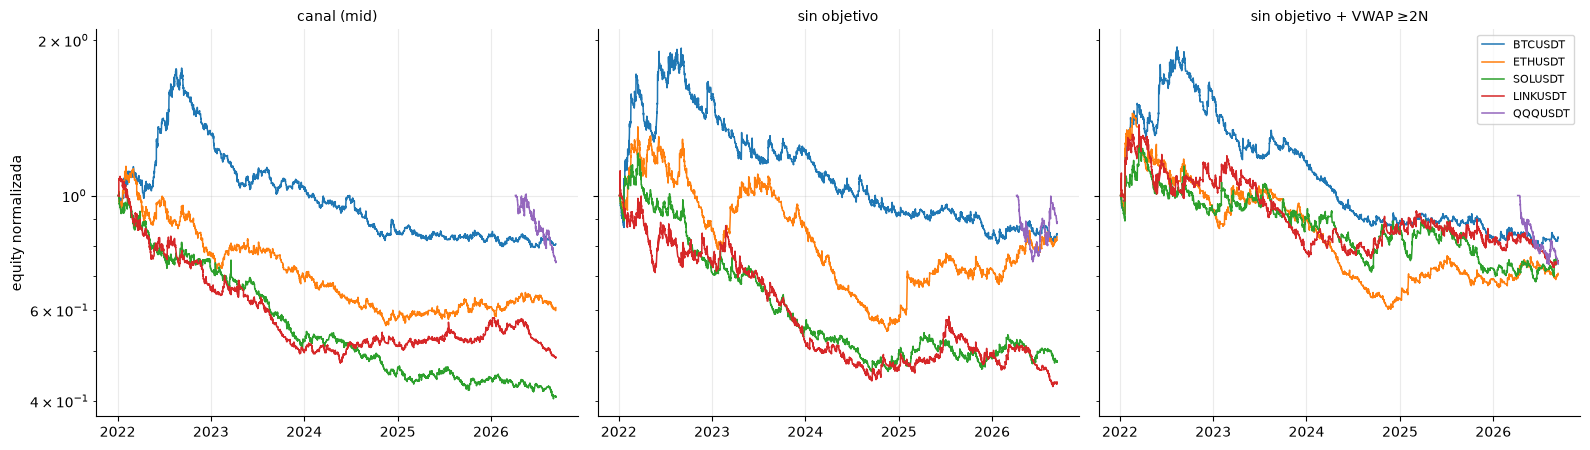

Mezcla media de salidas por sistema:


,canal (mid),sin objetivo,sin objetivo + VWAP ≥2N
reason,,,
stop,25.5%,32.8%,33.9%
stop_fuera,28.1%,38.6%,38.1%
target,23.9%,0.0%,0.0%
target_fuera,18.3%,0.0%,0.0%
vertical,4.3%,28.6%,28.0%


In [10]:
MAIN = f"sin objetivo + VWAP ≥{MIN_RANGE_N:.0f}N"

fig, axes = plt.subplots(1, len(SYSTEMS), figsize=(16, 4.6), sharey=True)
for ax, etiqueta in zip(np.atleast_1d(axes), SYSTEMS):
    for s in PILOT:
        ec = RESULTS[s][etiqueta][0]
        ax.plot(ec.index, ec / ec.iloc[0], lw=1.1, label=s)
    ax.set_yscale("log"); ax.set_title(etiqueta, fontsize=10)
np.atleast_1d(axes)[0].set_ylabel("equity normalizada")
np.atleast_1d(axes)[-1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Mezcla de salidas: con un objetivo a 10N la barrera temporal pasa a ser la
# salida dominante, y conviene verlo antes de llamar a esto "objetivo".
MIX = pd.DataFrame({
    etiqueta: pd.concat([RESULTS[s][etiqueta][1].reason.value_counts(normalize=True)
                         for s in PILOT], axis=1).mean(axis=1)
    for etiqueta in SYSTEMS}).fillna(0.0)
print("Mezcla media de salidas por sistema:")
display(MIX.style.format("{:.1%}"))


In [11]:
# Los números que sostienen la lectura de abajo, calculados en esta ejecución
# (no escritos a mano: cambian cada vez que cambia el motor).
_T = BASE_TABLE.set_index(["símbolo", "sistema"])
_main, _nof, _ch = MAIN, NOFILTER, "canal (mid)"
_crypto = [s for s in PILOT if s not in LATE]
def _rng(sistema, col):
    v = _T.loc[[(s, sistema) for s in _crypto], col]
    return v.min(), v.max()
print("Cripto, rango entre símbolos:")
for sistema in (_ch, _nof, _main):
    c0, c1 = _rng(sistema, "CAGR"); r0, r1 = _rng(sistema, "R media")
    w0, w1 = _rng(sistema, "win rate")
    print(f"  {sistema:<22} CAGR {c0:+.0%} … {c1:+.0%}   R media {r0:+.3f} … {r1:+.3f}"
          f"   acierto {w0:.0%} … {w1:.0%}")
print("\nEfecto del filtro VWAP (R media sin filtro -> con filtro):")
for s in PILOT:
    a, b = _T.loc[(s, _nof), "R media"], _T.loc[(s, _main), "R media"]
    print(f"  {s:<10} {a:+.3f} -> {b:+.3f}   ({'mejora' if b > a else 'empeora'})")
_cut = 1 - (_T.loc[[(s, _main) for s in _crypto], "trades"].sum()
            / _T.loc[[(s, _nof) for s in _crypto], "trades"].sum())
print(f"\nEl filtro recorta el {_cut:.0%} de las operaciones en las cripto.")
print(f"Mezcla de salidas del sistema principal: "
      + ", ".join(f"{k} {v:.0%}" for k, v in MIX[_main].items()))


Cripto, rango entre símbolos:
  canal (mid)            CAGR -17% … -5%   R media -0.177 … -0.073   acierto 39% … 43%
  sin objetivo           CAGR -16% … -4%   R media -0.163 … +0.003   acierto 23% … 26%
  sin objetivo + VWAP ≥2N CAGR -7% … -4%   R media -0.115 … -0.015   acierto 25% … 27%

Efecto del filtro VWAP (R media sin filtro -> con filtro):
  BTCUSDT    -0.059 -> -0.115   (empeora)
  ETHUSDT    +0.003 -> -0.096   (empeora)
  SOLUSDT    -0.163 -> -0.015   (mejora)
  LINKUSDT   -0.159 -> -0.036   (mejora)
  QQQUSDT    -0.078 -> -0.553   (empeora)

El filtro recorta el 22% de las operaciones en las cripto.
Mezcla de salidas del sistema principal: stop 34%, stop_fuera 38%, target 0%, target_fuera 0%, vertical 28%


### Lo que dice esta tabla, sin adornos

**Ninguno de los tres sistemas gana dinero** con las órdenes de salida evaluadas de noche (la
celda de arriba imprime los rangos). Es la diferencia central con las versiones anteriores de
este cuaderno, en las que "soltar el objetivo" convertía las cripto en ganadoras: lo que ganaba
era la ceguera nocturna. Un sistema que deja correr a sus ganadores durante 20 barras de sesión
—más de una noche— es exactamente el que más se beneficiaba de no ver los stops de madrugada:
las posiciones que sobrevivían eran las que el motor no podía ver morir.

**El acierto cae al 23-27 %.** Con la noche a la vista, más de un tercio de las salidas son
`stop_fuera`: un stop de 2N calibrado con la volatilidad de velas de 30 minutos no sobrevive a
17 horas de mercado sin mirar, ni a un fin de semana.

**El filtro de VWAP sigue siendo un lavado** —mejora unos símbolos y empeora otros—.


## §7. Barrido del umbral y del modo de VWAP

El 2N no se afirma: se sitúa. Si el resultado dependiera de acertar el umbral exacto, sería
sobreajuste; lo que hay que ver es una **tendencia** al endurecer el filtro, no un pico
aislado. El tamaño de esta rejilla es el `n_trials` que consume el DSR en §10 — buscar tiene
un precio y aquí se paga.


,modo,umbral N,CAGR,Sharpe,Max DD,trades,R media,vetos
0,rolling14,0.000000,-8.0%,-0.39,-63.3%,818,-0.126,0
1,rolling14,1.000000,-7.5%,-0.36,-62.2%,813,-0.121,9
2,rolling14,1.500000,-8.1%,-0.39,-64.8%,774,-0.166,134
3,rolling14,2.000000,-3.9%,-0.19,-59.1%,642,-0.115,645
4,rolling14,2.500000,-5.6%,-0.30,-56.3%,443,-0.143,1420
5,rolling14,3.000000,-11.6%,-0.91,-50.2%,267,-0.345,2100
6,rolling28,0.000000,+3.0%,0.11,-54.0%,823,+0.004,0
7,rolling28,1.000000,+1.9%,0.07,-55.9%,820,-0.004,11
8,rolling28,1.500000,+2.5%,0.10,-54.4%,807,-0.005,63
9,rolling28,2.000000,+3.4%,0.13,-57.0%,762,-0.021,200


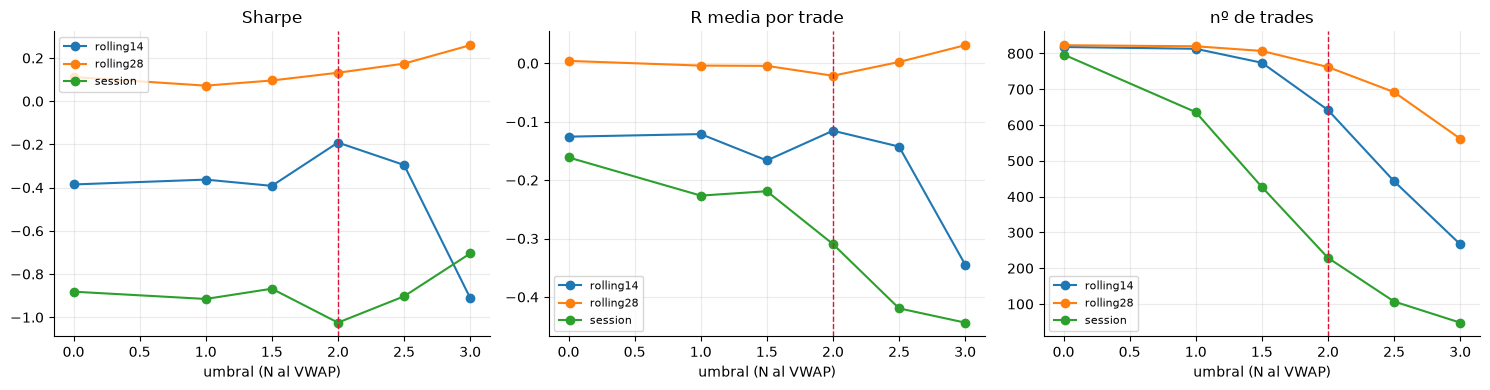

Configuraciones probadas: 18 aquí + 5 en la rejilla del WFO -> n_trials = 23


In [12]:
SWEEP_THRESHOLDS = [0.0, 1.0, 1.5, 2.0, 2.5, 3.0]
SWEEP_MODES = [("rolling", VWAP_BARS), ("rolling", 2 * VWAP_BARS), ("session", 0)]

sweep = []
for mode, bars in SWEEP_MODES:
    for thr in SWEEP_THRESHOLDS:
        pol = vwap_fade_policy(min_range_n=thr, vwap_mode=mode,
                               vwap_bars=bars or VWAP_BARS)
        ec, tr = run_backtest(df0, BASELINE, funding=FUNDING[FLAGSHIP], policy=pol,
                              path=PATHS.get(FLAGSHIP))
        m = equity_metrics(ec, tr, freq=FREQ)
        sweep.append({"modo": f"{mode}{bars or ''}", "umbral N": thr,
                      "CAGR": m.get("CAGR", np.nan), "Sharpe": m.get("Sharpe", np.nan),
                      "Max DD": m.get("Max DD", np.nan), "trades": int(len(tr)),
                      "R media": tr["r_multiple"].mean() if len(tr) else np.nan,
                      "vetos": tr.attrs["rejected"].get("poco_estirado", 0)})
SWEEP = pd.DataFrame(sweep)
display(SWEEP.style.format({"CAGR": "{:+.1%}", "Sharpe": "{:.2f}", "Max DD": "{:.1%}",
                            "R media": "{:+.3f}"}))
SWEEP.to_csv(OUT / "vwap_mr_threshold_sweep.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for modo, g in SWEEP.groupby("modo"):
    axes[0].plot(g["umbral N"], g["Sharpe"], marker="o", label=modo)
    axes[1].plot(g["umbral N"], g["R media"], marker="o", label=modo)
    axes[2].plot(g["umbral N"], g["trades"], marker="o", label=modo)
for ax, t in zip(axes, ["Sharpe", "R media por trade", "nº de trades"]):
    ax.axvline(MIN_RANGE_N, color="crimson", lw=1, ls="--")
    ax.set_xlabel("umbral (N al VWAP)"); ax.set_title(t); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
# n_trials del DSR: TODA la búsqueda, no solo este barrido. La rejilla del
# walk-forward (§9) también se probó sobre esta misma muestra y también cuenta;
# subestimar n_trials infla el DSR, que es justo lo que no se quiere.
N_TRIALS = len(SWEEP) + len(WFO_HOLDS)
print(f"Configuraciones probadas: {len(SWEEP)} aquí + {len(WFO_HOLDS)} en la rejilla "
      f"del WFO -> n_trials = {N_TRIALS}")


## §8. Cartera conjunta — una cuenta, topes compartidos

`run_portfolio_backtest` mete los cinco símbolos en **una sola cuenta**: el riesgo se mide
sobre el saldo total y los topes de apalancamiento bruto y de unidades por grupo son los de la
cartera en vivo. Repartir la equity y sumar curvas no responde a "qué hace una cuenta de 100k".

Aquí se comprueba además lo del arranque desfasado: **QQQ no puede tener un fill antes de su
primera barra**.


In [13]:
# Hereda de BASELINE: construir BacktestParams() de cero aquí perdería
# tp_mode/take_n y la cartera correría una estrategia distinta de la de §6.
PORT_P = BacktestParams(**{**BASELINE.__dict__,
                           "equity0": 100_000.0, "max_gross_lev": 4.0})
assert PORT_P.tp_mode == TP_MODE and PORT_P.take_n == TAKE_N
EC_P, TR_P, FILLS_P = run_portfolio_backtest(
    DATA, PORT_P, funding=FUNDING, corr_groups=CORR_GROUPS,
    max_dir_units=12, max_corr_units=6, policy=POLICY, paths=PATHS)

M_P = equity_metrics(EC_P, TR_P, freq=FREQ)
print("Cartera conjunta (VWAP ≥2N, 100k, 4x bruto):")
for k in ("CAGR", "Sharpe", "Sortino", "Max DD", "Calmar"):
    if k in M_P:
        print(f"  {k:<10}: {M_P[k]:.3f}")
print(f"  trades    : {len(TR_P)}")
print(f"  rechazos  : {TR_P.attrs['rejected']}")

print("\nPrimer fill por símbolo frente a su primera barra:")
for s in PILOT:
    f = FILLS_P[FILLS_P.symbol == s]
    primero = f.time.min() if len(f) else None
    ok = primero is None or primero >= DATA[s].index[0]
    print(f"  {s:<10} 1ª barra {DATA[s].index[0]}  1er fill {primero}  {'ok' if ok else 'VIOLACIÓN'}")
    assert ok, f"{s} operó antes de existir"
RAGGED_OK = True


Cartera conjunta (VWAP ≥2N, 100k, 4x bruto):
  CAGR      : -0.145
  Sharpe    : -0.399
  Sortino   : -0.506
  Max DD    : -0.785
  Calmar    : -0.184
  trades    : 2547
  rechazos  : {'apalancamiento': 22, 'topes': 3, 'poco_estirado': 2759}

Primer fill por símbolo frente a su primera barra:
  BTCUSDT    1ª barra 2022-01-03 14:30:00  1er fill 2022-01-04 19:30:00  ok
  ETHUSDT    1ª barra 2022-01-03 14:30:00  1er fill 2022-01-06 14:30:00  ok
  SOLUSDT    1ª barra 2022-01-03 14:30:00  1er fill 2022-01-05 19:00:00  ok
  LINKUSDT   1ª barra 2022-01-03 14:30:00  1er fill 2022-01-05 16:30:00  ok
  QQQUSDT    1ª barra 2026-04-06 13:30:00  1er fill 2026-04-14 18:30:00  ok


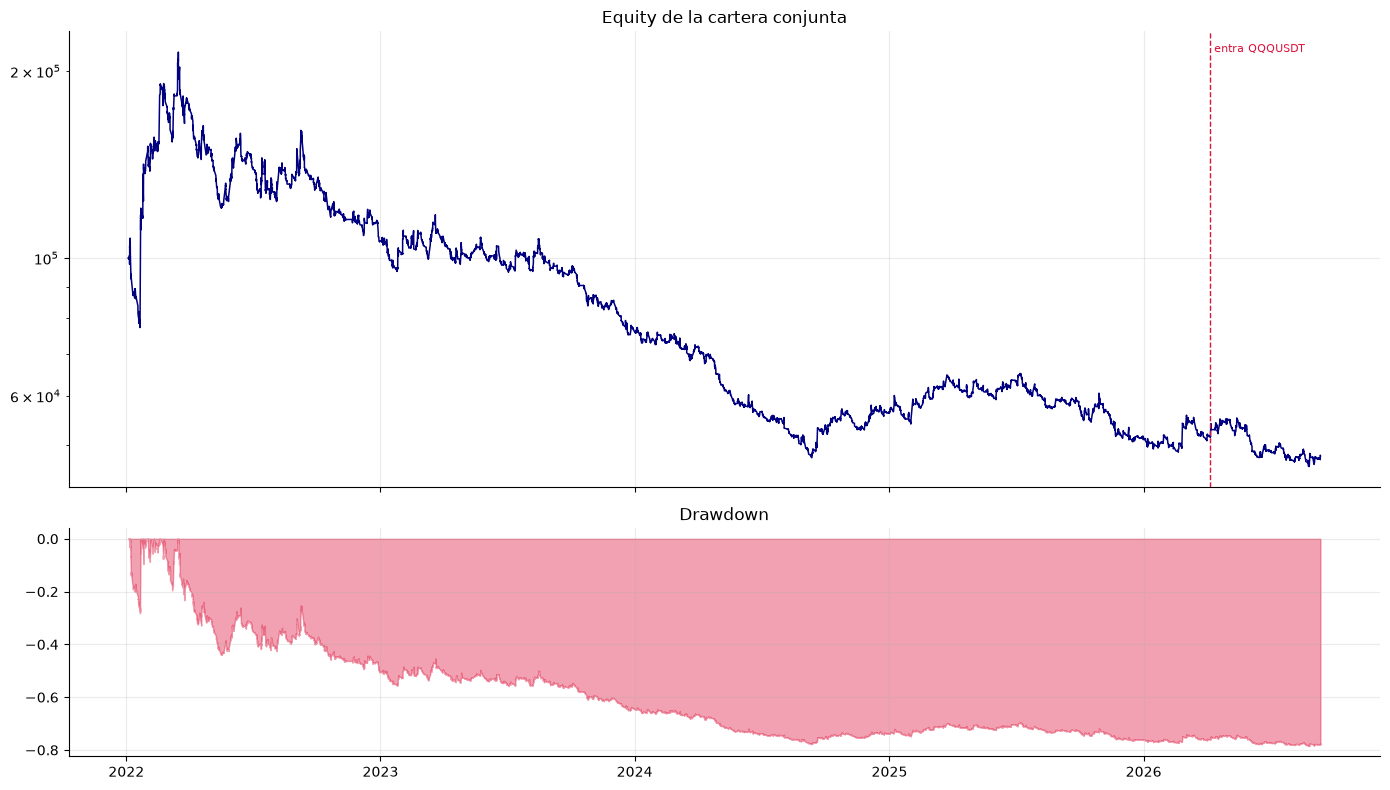

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(EC_P.index, EC_P, lw=1.1, color="navy")
for s in LATE:
    axes[0].axvline(DATA[s].index[0], color="crimson", ls="--", lw=1)
    axes[0].text(DATA[s].index[0], EC_P.max(), f" entra {s}", color="crimson", fontsize=8)
axes[0].set_yscale("log"); axes[0].set_title("Equity de la cartera conjunta")
dd = EC_P / EC_P.cummax() - 1
axes[1].fill_between(dd.index, dd, 0, color="crimson", alpha=0.4)
axes[1].set_title("Drawdown")
plt.tight_layout(); plt.show()


### §8.1 P&L por operación y de dónde sale el total

Sobre los trades de la **cartera** —una sola cuenta, así que los aportes suman al total de
verdad; sumar backtests por símbolo con 10.000 $ cada uno no daría la misma foto—.

Las dos preguntas que responden estos gráficos:

1. **¿Cómo es una operación típica?** Si la distribución tiene una cola derecha larga y una
   moda negativa apretada contra el stop, el sistema vive de pocos aciertos grandes, y entonces
   la media importa mucho menos que la cola.
2. **¿De cuántas operaciones depende el resultado?** La curva de Pareto lo hace literal: si el
   80 % del P&L sale del 5 % de los trades, la muestra efectiva no son 2.500 operaciones, son
   unas pocas decenas — y el intervalo de confianza real es mucho peor de lo que sugiere el
   número de trades.


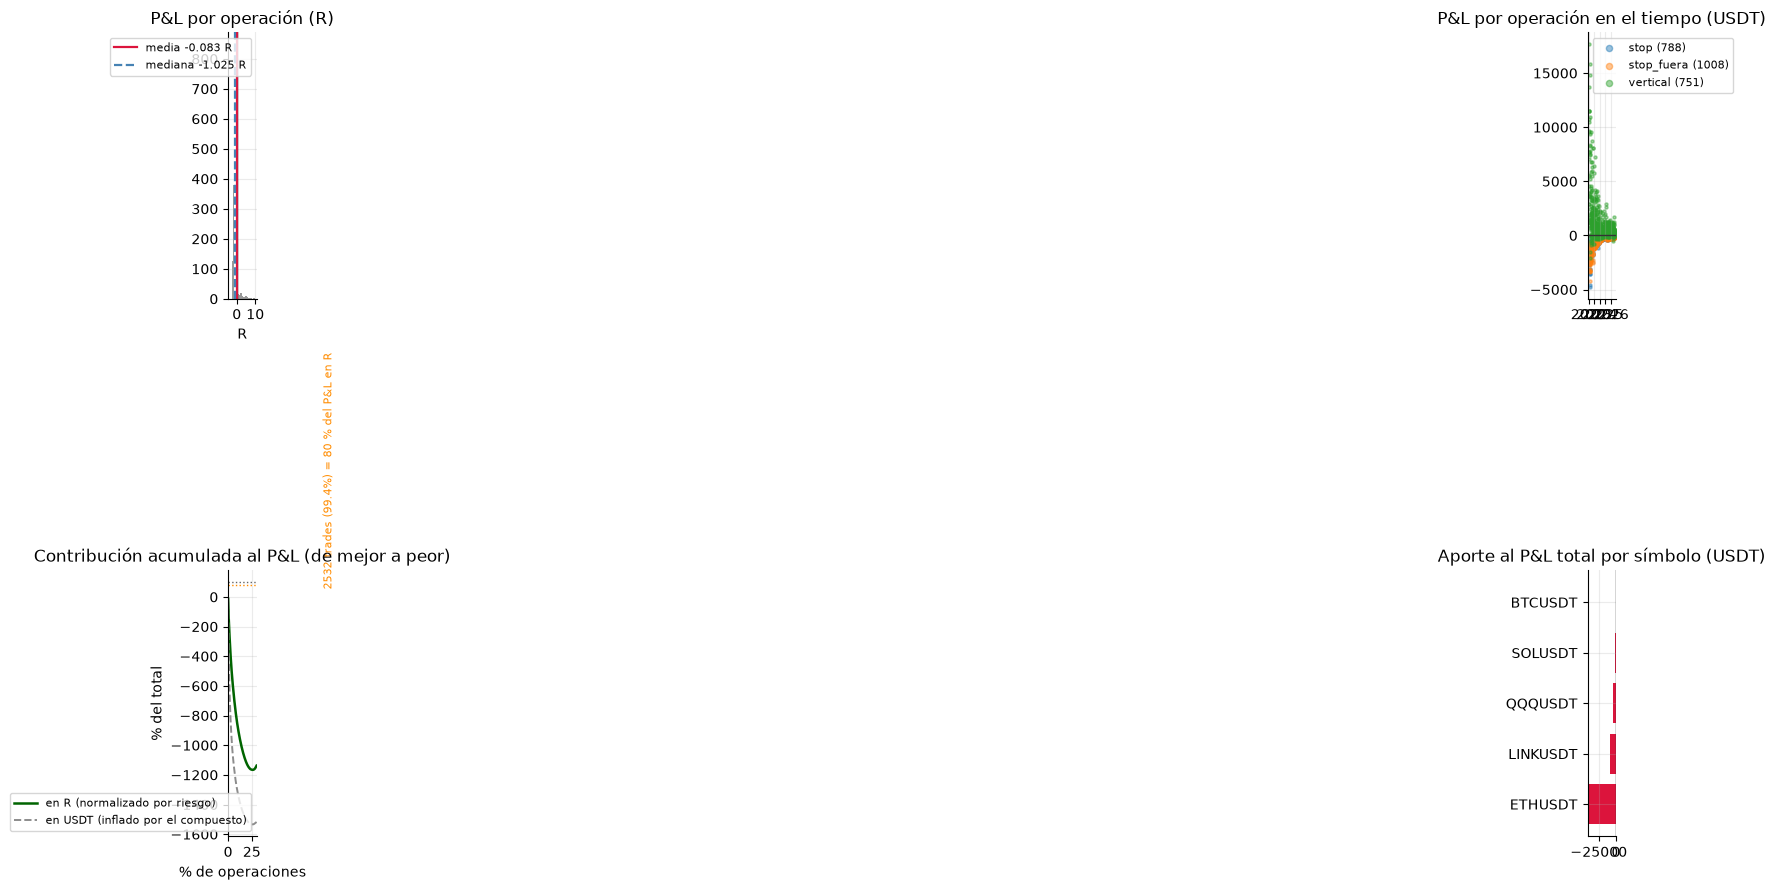

P&L realizado total: -52,629 USDT en 2547 operaciones


In [15]:
TRP = TR_P.copy()
TRP["mes"] = pd.to_datetime(TRP["closed"]).dt.to_period("M").dt.to_timestamp()
pnl_total = TRP["pnl"].sum()

fig, ax = plt.subplots(2, 2, figsize=(15, 9))

# (a) Distribución del P&L por operación, en R
r = TRP["r_multiple"].clip(-4, 10)
ax[0, 0].hist(r, bins=90, color="0.6")
ax[0, 0].axvline(0, color="0.2", lw=1)
ax[0, 0].axvline(TRP["r_multiple"].mean(), color="crimson", lw=1.6,
                 label=f"media {TRP['r_multiple'].mean():+.3f} R")
ax[0, 0].axvline(TRP["r_multiple"].median(), color="steelblue", lw=1.6, ls="--",
                 label=f"mediana {TRP['r_multiple'].median():+.3f} R")
ax[0, 0].set_title("P&L por operación (R)"); ax[0, 0].set_xlabel("R")
ax[0, 0].legend(fontsize=8)

# (b) P&L por operación en el tiempo, por motivo de salida
for motivo, g in TRP.groupby("reason"):
    ax[0, 1].scatter(pd.to_datetime(g["closed"]), g["pnl"], s=5, alpha=0.45,
                     label=f"{motivo} ({len(g)})")
ax[0, 1].axhline(0, color="0.2", lw=1)
ax[0, 1].set_title("P&L por operación en el tiempo (USDT)")
ax[0, 1].legend(fontsize=8, markerscale=2)

# (c) Pareto, en dos medidas. La de USDT está inflada por el interés
# compuesto —la cuenta va de 100k a millones, así que una operación tardía
# mueve más dinero que una temprana por construcción, no por ser mejor—.
# La de R normaliza por el riesgo asumido y es la que hay que leer.
def pareto(serie):
    o = np.sort(serie.to_numpy())[::-1]
    return np.arange(1, len(o) + 1) / len(o), np.cumsum(o) / o.sum()

x_u, cum_u = pareto(TRP["pnl"])
x_r, cum_r = pareto(TRP["r_multiple"])
ax[1, 0].plot(100 * x_r, 100 * cum_r, lw=1.8, color="darkgreen",
              label="en R (normalizado por riesgo)")
ax[1, 0].plot(100 * x_u, 100 * cum_u, lw=1.4, color="0.55", ls="--",
              label="en USDT (inflado por el compuesto)")
ax[1, 0].axhline(100, color="0.4", lw=1, ls=":")
ax[1, 0].axhline(80, color="darkorange", lw=1, ls=":")
k80 = int(np.searchsorted(cum_r, 0.80) + 1)
ax[1, 0].axvline(100 * k80 / len(x_r), color="darkorange", lw=1, ls="--")
ax[1, 0].text(100 * k80 / len(x_r), 15,
              f"  {k80} trades ({k80/len(x_r):.1%}) = 80 % del P&L en R",
              color="darkorange", fontsize=8, rotation=90)
ax[1, 0].set_xlim(0, 30)
ax[1, 0].set_title("Contribución acumulada al P&L (de mejor a peor)")
ax[1, 0].set_xlabel("% de operaciones"); ax[1, 0].set_ylabel("% del total")
ax[1, 0].legend(fontsize=8, loc="lower right")

# (d) Aporte al P&L total por símbolo
por_sim = TRP.groupby("symbol")["pnl"].sum().sort_values()
colores = ["crimson" if v < 0 else "steelblue" for v in por_sim]
ax[1, 1].barh(por_sim.index, por_sim.to_numpy(), color=colores)
ax[1, 1].axvline(0, color="0.2", lw=1)
ax[1, 1].set_title("Aporte al P&L total por símbolo (USDT)")
plt.tight_layout(); plt.show()

print(f"P&L realizado total: {pnl_total:,.0f} USDT en {len(TRP)} operaciones")


In [16]:
def aporte(col):
    g = TRP.groupby(col).agg(trades=("pnl", "size"), pnl=("pnl", "sum"),
                             R_media=("r_multiple", "mean"),
                             acierto=("pnl", lambda s: (s > 0).mean()))
    g["% del P&L"] = g["pnl"] / pnl_total
    return g.sort_values("pnl", ascending=False)

print("Aporte por símbolo:")
display(aporte("symbol").style.format({"pnl": "{:,.0f}", "R_media": "{:+.3f}",
                                       "acierto": "{:.1%}", "% del P&L": "{:+.1%}"}))
print("Aporte por motivo de salida:")
display(aporte("reason").style.format({"pnl": "{:,.0f}", "R_media": "{:+.3f}",
                                       "acierto": "{:.1%}", "% del P&L": "{:+.1%}"}))

# Concentración, en la forma en que muerde: cuántas operaciones hacen el 50 %.
# Se reportan las DOS medidas porque cuentan cosas distintas.
for etiqueta, col in (("USDT (con compuesto)", "pnl"), ("R (por riesgo)", "r_multiple")):
    o = np.sort(TRP[col].to_numpy())[::-1]
    c = np.cumsum(o) / o.sum()
    n50 = int(np.searchsorted(c, 0.50) + 1)
    n80 = int(np.searchsorted(c, 0.80) + 1)
    print(f"{etiqueta:<22}: 50 % del total en {n50} trades ({n50/len(o):.2%}), "
          f"80 % en {n80} ({n80/len(o):.2%}); top-10 = {100*c[9]:.1f} %")
print("\nLa fila en USDT está inflada por el interés compuesto: con la cuenta creciendo\n"
      "de 100k a millones, una operación tardía mueve más dinero que una temprana\n"
      "aunque sea peor. La fila en R es la que mide concentración de verdad.")


Aporte por símbolo:


,trades,pnl,R_media,acierto,% del P&L
symbol,,,,,
BTCUSDT,642,-145,-0.126,27.1%,+0.3%
SOLUSDT,612,"-1,469",-0.007,26.8%,+2.8%
QQQUSDT,61,"-3,662",-0.555,16.4%,+7.0%
LINKUSDT,616,"-8,051",-0.035,25.6%,+15.3%
ETHUSDT,616,"-39,302",-0.117,24.8%,+74.7%


Aporte por motivo de salida:


,trades,pnl,R_media,acierto,% del P&L
reason,,,,,
vertical,751,"788,994",+3.218,87.6%,-1499.2%
stop,788,"-336,416",-1.391,0.1%,+639.2%
stop_fuera,1008,"-505,208",-1.521,0.0%,+959.9%


USDT (con compuesto)  : 50 % del total en 2541 trades (99.76%), 80 % en 2545 (99.92%); top-10 = -244.6 %
R (por riesgo)        : 50 % del total en 2508 trades (98.47%), 80 % en 2532 (99.41%); top-10 = -99.9 %

La fila en USDT está inflada por el interés compuesto: con la cuenta creciendo
de 100k a millones, una operación tardía mueve más dinero que una temprana
aunque sea peor. La fila en R es la que mide concentración de verdad.


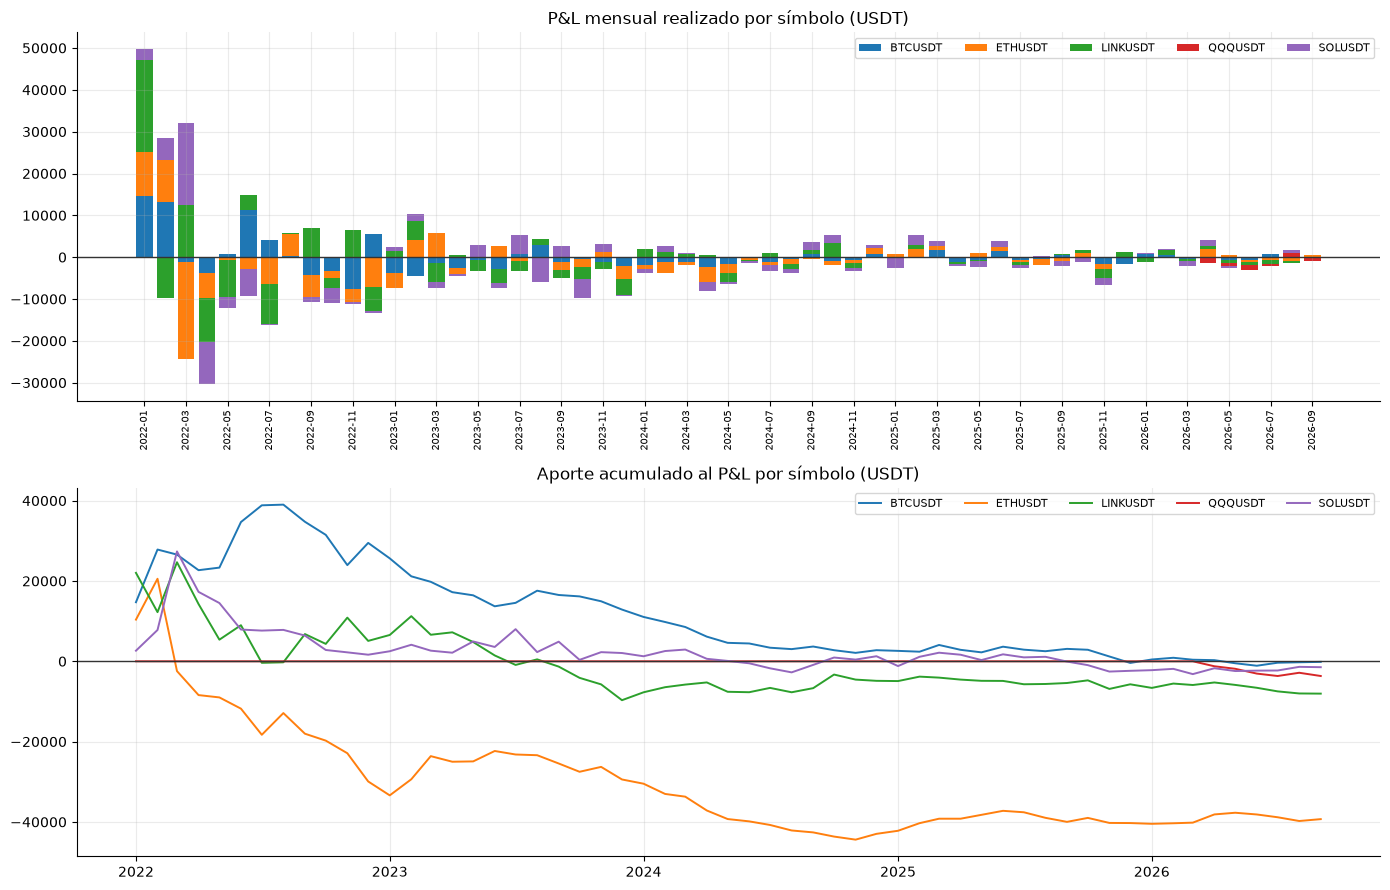

Meses en positivo: 31.6% de 57


In [17]:
# P&L mensual y aporte acumulado por símbolo: dónde y cuándo se ganó
mensual = TRP.pivot_table(index="mes", columns="symbol", values="pnl",
                          aggfunc="sum").fillna(0.0)
# Sin sharex: el de barras usa eje categórico y el de líneas eje temporal;
# compartirlos hace que pandas intente convertir fechas a Period y reviente.
fig, ax = plt.subplots(2, 1, figsize=(14, 9))
etiquetas = [d.strftime("%Y-%m") for d in mensual.index]
abajo_pos = np.zeros(len(mensual)); abajo_neg = np.zeros(len(mensual))
for s in mensual.columns:
    v = mensual[s].to_numpy()
    pos, neg = np.clip(v, 0, None), np.clip(v, None, 0)
    ax[0].bar(etiquetas, pos, bottom=abajo_pos, label=s)
    ax[0].bar(etiquetas, neg, bottom=abajo_neg, color=ax[0].containers[-1][0].get_facecolor())
    abajo_pos += pos; abajo_neg += neg
ax[0].axhline(0, color="0.2", lw=1)
ax[0].set_title("P&L mensual realizado por símbolo (USDT)")
ax[0].set_xticks(range(0, len(etiquetas), 2))
ax[0].set_xticklabels(etiquetas[::2], rotation=90, fontsize=7)
ax[0].legend(fontsize=8, ncol=len(PILOT))

acum = mensual.cumsum()
for s in acum.columns:
    ax[1].plot(acum.index, acum[s], lw=1.4, label=s)
ax[1].axhline(0, color="0.2", lw=1)
ax[1].set_title("Aporte acumulado al P&L por símbolo (USDT)")
ax[1].legend(fontsize=8, ncol=len(PILOT))
plt.tight_layout(); plt.show()

positivos = (mensual.sum(axis=1) > 0).mean()
print(f"Meses en positivo: {positivos:.1%} de {len(mensual)}")


### §8.2 ¿Gana el objetivo o gana la barrera temporal?

§8.1 muestra que el objetivo de `take_n` casi no se toca (~2 % de las salidas) y que, de las
posiciones que no acaban en el stop, casi todas las cierra la barrera de `max_hold_bars`. La
hipótesis a contrastar: el barrido de `take_n` no estaba midiendo un objetivo, sino cuánto
tiempo se deja correr la posición.

La prueba directa tiene dos partes:

1. **`max_hold_bars` con `take_n` fijo.** Si la esperanza se mueve con las barras, el horizonte
   de salida es un parámetro que importa.
2. **La rejilla cruzada `take_n × max_hold_bars`.** Es la que separa los dos efectos. Si el mapa
   de calor cambia sobre todo **a lo largo de las columnas** (barras) y casi nada **a lo largo
   de las filas** (objetivo), el take-profit es decorativo. Incluye una fila de `take_n` = 50N
   —un objetivo que no se toca nunca— y una columna "sin barrera", para ver cada efecto con el
   otro apagado.

Se corre sobre las cuatro cripto, sin filtro de VWAP (el filtro no sobrevivió fuera de muestra
en §9) y sin QQQ (0,4 años no sostienen una rejilla).

**Esto también es búsqueda sobre la misma muestra.** Sus configuraciones se suman a `n_trials`
del DSR en §10: diagnosticar mirando resultados tiene el mismo precio que optimizar.


In [18]:
CRYPTO = [s for s in PILOT if s not in LATE]
NO_BARRIER = 100_000          # una barrera que nunca llega

def run_exit_cfg(take_n, max_hold):
    # Media sobre las cripto de un par (take_n, max_hold_bars), sin filtro VWAP.
    filas, mezclas = [], []
    for s in CRYPTO:
        p = BacktestParams(**{**BASELINE.__dict__,
                              "take_n": float(take_n), "max_hold_bars": int(max_hold)})
        ec, tr = run_backtest(DATA[s], p, funding=FUNDING[s], path=PATHS.get(s))
        m = equity_metrics(ec, tr, freq=FREQ)
        filas.append((m.get("CAGR", np.nan), m.get("Sharpe", np.nan),
                      m.get("Max DD", np.nan), len(tr),
                      tr["r_multiple"].mean() if len(tr) else np.nan,
                      tr["bars_held"].mean() if len(tr) else np.nan))
        mezclas.append(tr["reason"].value_counts(normalize=True))
    a = np.array(filas, dtype=float)
    mix = pd.concat(mezclas, axis=1).mean(axis=1)
    return {"CAGR": a[:, 0].mean(), "Sharpe": a[:, 1].mean(), "Max DD": a[:, 2].mean(),
            "trades": a[:, 3].mean(), "R media": a[:, 4].mean(),
            "barras medias": a[:, 5].mean(),
            "% vertical": mix.get("vertical", 0.0), "% target": mix.get("target", 0.0),
            "% stop": mix.get("stop", 0.0)}

# (1) max_hold_bars con take_n fijo
HOLDS = [5, 10, 15, 20, 30, 45, 60, NO_BARRIER]
HOLD_SWEEP = pd.DataFrame([{"max_hold_bars": h, **run_exit_cfg(TAKE_N, h)} for h in HOLDS])
HOLD_SWEEP["max_hold_bars"] = HOLD_SWEEP["max_hold_bars"].replace(NO_BARRIER, "sin barrera")
print(f"take_n fijo en {TAKE_N:.0f}N, media de {CRYPTO}:")
display(HOLD_SWEEP.style.format({
    "CAGR": "{:+.1%}", "Sharpe": "{:.2f}", "Max DD": "{:.1%}", "trades": "{:.0f}",
    "R media": "{:+.3f}", "barras medias": "{:.1f}",
    "% vertical": "{:.1%}", "% target": "{:.1%}", "% stop": "{:.1%}"}))


take_n fijo en 50N, media de ['BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'LINKUSDT']:


,max_hold_bars,CAGR,Sharpe,Max DD,trades,R media,barras medias,% vertical,% target,% stop
0,5,-8.8%,-0.70,-46.8%,1031,-0.071,4.3,71.1%,0.0%,15.4%
1,10,-7.1%,-0.52,-57.4%,919,-0.086,7.3,47.6%,0.0%,25.4%
2,15,-8.2%,-0.43,-57.2%,846,-0.071,9.0,32.0%,0.0%,29.9%
3,20,-9.6%,-0.48,-60.5%,802,-0.094,10.5,27.9%,0.0%,32.2%
4,30,-7.3%,-0.29,-59.8%,728,-0.057,12.9,20.0%,0.0%,35.6%
5,45,-4.1%,-0.14,-58.4%,648,-0.003,15.6,16.0%,0.0%,37.1%
6,60,-6.1%,-0.18,-60.2%,605,-0.001,17.6,12.7%,0.0%,37.7%
7,sin barrera,-9.7%,-0.40,-64.2%,183,-0.282,82.6,0.0%,1.2%,41.4%


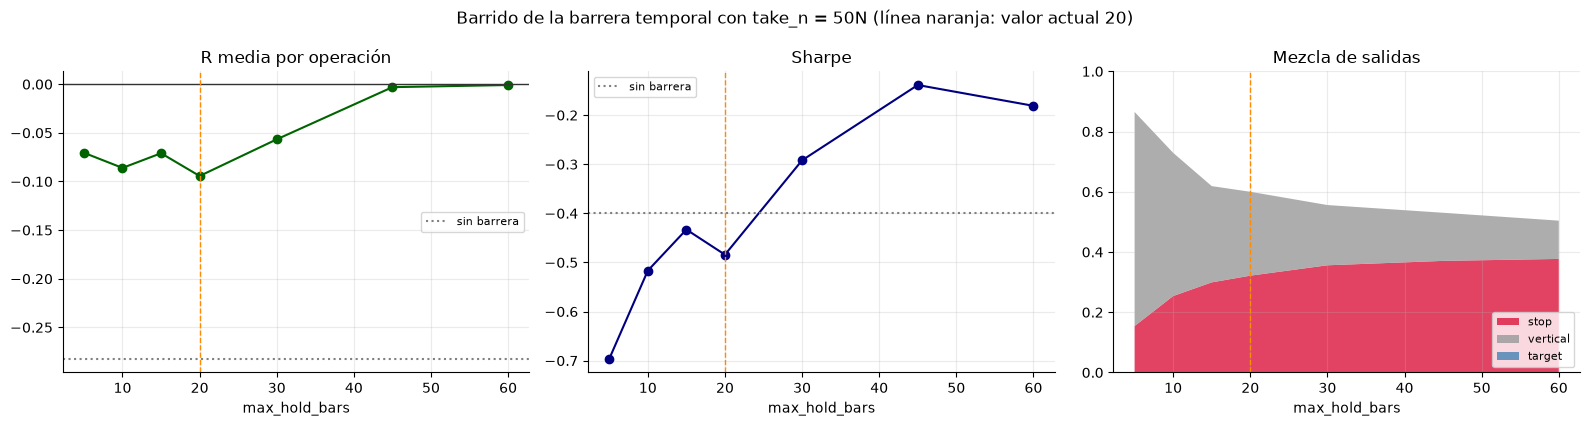

R media: -0.071 (5 barras) -> -0.282 (sin barrera)
Sharpe máximo -0.14 en max_hold_bars = 45; sin barrera -0.40
Max DD: -47% (5) -> -64% (sin barrera)


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
hs = HOLD_SWEEP[HOLD_SWEEP["max_hold_bars"] != "sin barrera"]
x = hs["max_hold_bars"].astype(int)
sin = HOLD_SWEEP[HOLD_SWEEP["max_hold_bars"] == "sin barrera"].iloc[0]

ax[0].plot(x, hs["R media"], marker="o", color="darkgreen")
ax[0].axhline(sin["R media"], color="0.5", ls=":", label="sin barrera")
ax[0].axhline(0, color="0.2", lw=1)
ax[0].set_title("R media por operación"); ax[0].legend(fontsize=8)

ax[1].plot(x, hs["Sharpe"], marker="o", color="navy")
ax[1].axhline(sin["Sharpe"], color="0.5", ls=":", label="sin barrera")
ax[1].set_title("Sharpe"); ax[1].legend(fontsize=8)

ax[2].stackplot(x, hs["% stop"], hs["% vertical"], hs["% target"],
                labels=["stop", "vertical", "target"],
                colors=["crimson", "0.6", "steelblue"], alpha=0.8)
ax[2].set_ylim(0, 1); ax[2].set_title("Mezcla de salidas")
ax[2].legend(fontsize=8, loc="lower right")

for a in ax:
    a.axvline(BASELINE.max_hold_bars, color="darkorange", ls="--", lw=1)
    a.set_xlabel("max_hold_bars")
plt.suptitle(f"Barrido de la barrera temporal con take_n = {TAKE_N:.0f}N "
             f"(línea naranja: valor actual {BASELINE.max_hold_bars})")
plt.tight_layout(); plt.show()

_hs = HOLD_SWEEP.copy()
_b = _hs.loc[_hs.Sharpe.idxmax()]
print(f"R media: {_hs['R media'].iloc[0]:+.3f} ({_hs.max_hold_bars.iloc[0]} barras) -> "
      f"{_hs['R media'].iloc[-1]:+.3f} ({_hs.max_hold_bars.iloc[-1]})")
print(f"Sharpe máximo {_b.Sharpe:.2f} en max_hold_bars = {_b.max_hold_bars}; "
      f"sin barrera {_hs.Sharpe.iloc[-1]:.2f}")
print(f"Max DD: {_hs['Max DD'].iloc[0]:.0%} ({_hs.max_hold_bars.iloc[0]}) -> "
      f"{_hs['Max DD'].iloc[-1]:.0%} (sin barrera)")


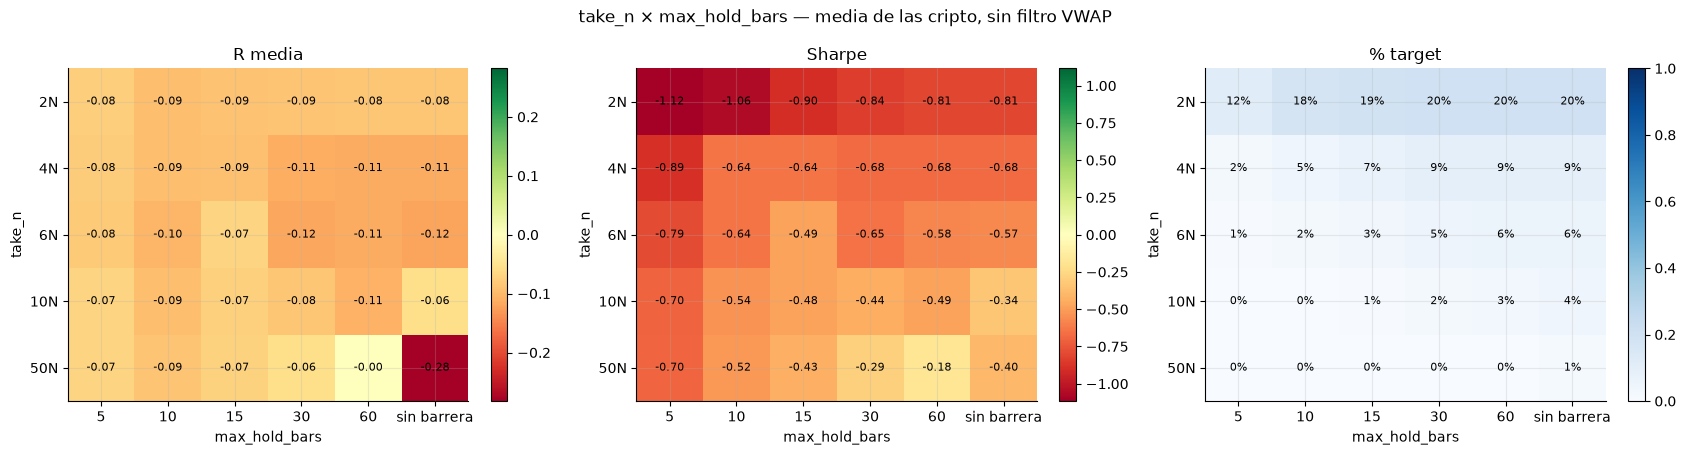

In [20]:
# (2) Rejilla cruzada: separa el efecto del objetivo del de la barrera
TAKES = [2.0, 4.0, 6.0, 10.0, 50.0]
HOLDS_X = [5, 10, 15, 30, 60, NO_BARRIER]
grid = []
for tn in TAKES:
    for h in HOLDS_X:
        grid.append({"take_n": tn, "max_hold_bars": h, **run_exit_cfg(tn, h)})
EXIT_GRID = pd.DataFrame(grid)
col_lbl = {h: ("sin barrera" if h == NO_BARRIER else str(h)) for h in HOLDS_X}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, metrica, fmt, cmap in ((ax[0], "R media", "{:+.2f}", "RdYlGn"),
                              (ax[1], "Sharpe", "{:.2f}", "RdYlGn"),
                              (ax[2], "% target", "{:.0%}", "Blues")):
    M = EXIT_GRID.pivot(index="take_n", columns="max_hold_bars", values=metrica)
    M = M[HOLDS_X]
    if cmap == "RdYlGn":
        lim = np.nanmax(np.abs(M.to_numpy()))
        im = a.imshow(M.to_numpy(), cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")
    else:
        im = a.imshow(M.to_numpy(), cmap=cmap, vmin=0, vmax=1, aspect="auto")
    a.set_xticks(range(len(HOLDS_X))); a.set_xticklabels([col_lbl[h] for h in HOLDS_X])
    a.set_yticks(range(len(TAKES))); a.set_yticklabels([f"{t:.0f}N" for t in TAKES])
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            a.text(j, i, fmt.format(M.iat[i, j]), ha="center", va="center", fontsize=8)
    a.set_xlabel("max_hold_bars"); a.set_ylabel("take_n")
    a.set_title(metrica)
    plt.colorbar(im, ax=a, fraction=0.046)
plt.suptitle("take_n × max_hold_bars — media de las cripto, sin filtro VWAP")
plt.tight_layout(); plt.show()


In [21]:
# Cuánto explica cada eje. Rango de la R media al mover UN parámetro con el
# otro fijo, promediado sobre los valores del otro: es la forma más simple de
# decir cuál de los dos manda sin ajustar ningún modelo.
R = EXIT_GRID.pivot(index="take_n", columns="max_hold_bars", values="R media")[HOLDS_X]
efecto_barrera  = (R.max(axis=1) - R.min(axis=1)).mean()   # moviendo columnas
efecto_objetivo = (R.max(axis=0) - R.min(axis=0)).mean()   # moviendo filas
print(f"Rango medio de la R al mover max_hold_bars (take_n fijo): {efecto_barrera:.3f} R")
print(f"Rango medio de la R al mover take_n (max_hold_bars fijo): {efecto_objetivo:.3f} R")
print(f"Cociente barrera/objetivo: {efecto_barrera / efecto_objetivo:.2f}x")

# Los dos extremos "con el otro apagado"
solo_objetivo = R.loc[:, NO_BARRIER]            # sin barrera, variando take_n
solo_barrera  = R.loc[50.0, :]                  # objetivo inalcanzable, variando barras
print("\nSin barrera temporal, solo el objetivo decide:")
print("  " + "  ".join(f"{t:.0f}N={v:+.3f}" for t, v in solo_objetivo.items()))
print("Con objetivo inalcanzable (50N), solo la barrera decide:")
print("  " + "  ".join(f"{col_lbl[h]}={v:+.3f}" for h, v in solo_barrera.items()))

# Estas configuraciones también se probaron sobre esta muestra: cuentan.
EXIT_TRIALS = len(EXIT_GRID) + len(set(HOLDS) - set(HOLDS_X))
N_TRIALS += EXIT_TRIALS
print(f"\n+{EXIT_TRIALS} configuraciones de diagnóstico -> n_trials del DSR = {N_TRIALS}")


Rango medio de la R al mover max_hold_bars (take_n fijo): 0.088 R
Rango medio de la R al mover take_n (max_hold_bars fijo): 0.075 R
Cociente barrera/objetivo: 1.18x

Sin barrera temporal, solo el objetivo decide:
  2N=-0.084  4N=-0.114  6N=-0.121  10N=-0.056  50N=-0.282
Con objetivo inalcanzable (50N), solo la barrera decide:
  5=-0.071  10=-0.086  15=-0.071  30=-0.057  60=-0.001  sin barrera=-0.282

+32 configuraciones de diagnóstico -> n_trials del DSR = 55


### Lo que dice §8.2

**Con los stops evaluados de noche, ninguna combinación de objetivo y barrera temporal es
rentable** (celdas de arriba). La versión anterior de esta sección concluía que `take_n` y
`max_hold_bars` eran dos palancas para "dejar correr a los ganadores", y que cualquiera de las
dos, relajada, subía la R media hasta +0,67 R. Ese resultado era la ceguera nocturna: dejar
correr significaba cruzar más noches, y cada noche era un tramo del camino en el que el motor
no podía ejecutar el stop. Más horizonte, más ceguera, más "R".

Lo que queda en pie es modesto: los dos parámetros siguen moviendo la R media en órdenes de
magnitud parecidos, y ambos dentro de valores negativos. Validar uno solo (§9) sigue siendo
la decisión correcta, pero ya no hay nada que optimizar que tenga signo positivo.


### §8.3 MAE / MFE respecto del stop de 2N

Réplica de la §8.5 de `Turtle_IBKR_CME_Bitcoin.ipynb`, sobre este sistema: objetivo apagado,
filtro VWAP, sesión regular, **stop operado de 2N** (1R = 2N). La pregunta es si la excursión
adversa (MAE) contiene información sobre el desenlace y, si la contiene, **si hay sitio dentro
del stop de 2N para un cierre temprano**.

**El orden de lectura importa.** Primero la curva `P(ganador | MAE ≥ x)`. Si es plana, la MAE no
dice nada del desenlace, cortar por ella solo añade coste, y ningún Sharpe posterior salva el
argumento. Solo si cae con claridad tiene sentido buscar un umbral.

**Tres poblaciones de observación.** El stop trunca el camino y por tanto trunca la MAE que se
puede ver: con un stop de 2N, ningún trade puede mostrar más de 2N de MAE, y el cuantil de los
ganadores sale pegado al propio stop — se estaría midiendo el stop, no el mercado. Se observan
tres regímenes de barrera (**sin stop, 3N y 2N**) manteniendo **siempre R = 2N**, y el
desplazamiento de MAE\* entre ellos **es** el sesgo de truncamiento, medido. Se calibra con el
régimen de **3N** —más ancho que el operado— por la misma razón que el cuaderno original
calibraba a 2N operando a 1N.

**Separar barrera y unidad de riesgo.** Para esto el motor tiene ahora `mae_stop_n`: la R la fija
`stop_n` (sizing y `r_multiple`) y `mae_stop_n` fija dónde se cierra. `inf` = sin stop.

**Suelo de resolución.** Un umbral por debajo del rango típico de una vela no se distingue
dentro de la barra: el backtest estaría inventando un orden de eventos que no observó. Se mide y
se sombrea en todos los paneles.

**Cómo se mide la excursión en este motor.** Desde el primer fill (`entry0`) y en unidades del N
congelado, sobre las mismas barras en que se evalúan las barreras (desde la barra siguiente al
fill). En la barra de un stop la MAE se fija en el stop y no se acredita MFE (prelación
pesimista); en la de un objetivo la MFE se fija en el objetivo.


In [22]:
from qsCrypto.portfolio.mae import mae_star, win_prob_curve, edge_ratio

STOP_N = BASELINE.stop_n            # 2N: el stop que se opera y la unidad R
CALIB_STOP_N = 3.0                  # barrera más ancha para calibrar
DATA_C = {s: DATA[s] for s in CRYPTO}

def bar_range_n(d):
    n = compute_n(d["high"].to_numpy(float), d["low"].to_numpy(float),
                  d["close"].to_numpy(float), period=BASELINE.atr_period)
    return pd.Series((d["high"] - d["low"]).to_numpy(float) / n, index=d.index)

FLOOR_N = float(pd.concat([bar_range_n(d) for d in DATA_C.values()]).dropna().median())

def observe(barrier_n):
    # Población de observación: el sistema operado con otra barrera, R = STOP_N
    # siempre. Sin regla de drawdown: una población de calibración no debe
    # encoger su propio tamaño y vaciar la muestra en silencio.
    p = BacktestParams(**{**BASELINE.__dict__, "mae_stop_n": barrier_n,
                          "use_dd_rule": False})
    trs = []
    for s, d in DATA_C.items():
        _, tr = run_backtest(d, p, funding=FUNDING[s], policy=POLICY,
                             path=PATHS.get(s))
        trs.append(tr.assign(symbol=s))
    tr = pd.concat(trs, ignore_index=True)
    tr["win"] = tr["pnl"] > 0
    return tr

GRID_X = np.arange(0.0, 4.01, 0.25)
REGIMES, CALIB = {}, []
for lbl, barrier in [("sin stop", float("inf")),
                     (f"stop {CALIB_STOP_N:.0f}N", CALIB_STOP_N),
                     (f"stop {STOP_N:.0f}N (operado)", STOP_N)]:
    tr = observe(barrier)
    fb = STOP_N if not np.isfinite(barrier) else barrier
    star, info = mae_star(tr.mae_n, tr.win, q=0.90, min_winners=30,
                          flat_frac=tr.flat_frac, resolvable_floor=FLOOR_N, fallback=fb)
    cur = win_prob_curve(tr.mae_n, tr.win, grid=GRID_X)
    res = cur[cur.x_n >= FLOOR_N]
    REGIMES[lbl] = {"trades": tr, "star": star, "info": info, "curve": cur, "barrier": barrier}
    CALIB.append({
        "régimen": lbl, "R": f"{STOP_N:.0f}N", "trades": len(tr),
        "ganadores": int(tr.win.sum()), "tasa_acierto": tr.win.mean(),
        "R media": tr.r_multiple.mean(),
        "salidas vertical": (tr.reason == "vertical").mean(),
        "MAE_p50_gan": tr.loc[tr.win, "mae_n"].median(),
        "MAE_p90_gan": tr.loc[tr.win, "mae_n"].quantile(.90),
        "MAE*_N": star, "MAE*_R": star / STOP_N,
        "lift": res.lift.mean(), "KS": cur.ks.max(),
        "E-ratio": edge_ratio(tr.mfe_n, tr.mae_n),
        "fallback": info["fallback_usado"],
    })
CALIB = pd.DataFrame(CALIB)

print("=" * 82)
print("  POBLACIONES DE CALIBRACIÓN — la barrera cambia lo que se puede ver (R = 2N siempre)")
print("=" * 82)
print(f"\n  Suelo de resolución intrabarra: {FLOOR_N:.2f} N (rango mediano de vela, {INTERVAL})")
display(CALIB.style.format({
    "tasa_acierto": "{:.0%}", "R media": "{:+.3f}", "salidas vertical": "{:.0%}",
    "MAE_p50_gan": "{:.2f}", "MAE_p90_gan": "{:.2f}", "MAE*_N": "{:.2f}",
    "MAE*_R": "{:.2f}", "lift": "{:+.3f}", "KS": "{:.2f}", "E-ratio": "{:.2f}"}))

_KEY = f"stop {CALIB_STOP_N:.0f}N"
TR_OBS   = REGIMES[_KEY]["trades"]
MAE_STAR = REGIMES[_KEY]["star"]
CUR      = REGIMES[_KEY]["curve"]
W, L = TR_OBS[TR_OBS.win], TR_OBS[~TR_OBS.win]

print(f"\n  Régimen de referencia: {_KEY}  ->  MAE* = {MAE_STAR:.2f} N = "
      f"{MAE_STAR/STOP_N:.2f} R")
print(f"  E-ratio (MFE/MAE)    : {edge_ratio(TR_OBS.mfe_n, TR_OBS.mae_n):.2f}"
      "   (<1 => la ENTRADA no tiene ventaja direccional inmediata)")
_sp = CALIB.set_index("régimen")["MAE*_N"]
print(f"\n  Sesgo de truncamiento: MAE* va de {_sp.min():.2f}N a {_sp.max():.2f}N según la "
      f"barrera con que se observe ({_sp.max()/max(_sp.min(), 1e-9):.1f}x).")


  POBLACIONES DE CALIBRACIÓN — la barrera cambia lo que se puede ver (R = 2N siempre)

  Suelo de resolución intrabarra: 0.76 N (rango mediano de vela, 30m)


,régimen,R,trades,ganadores,tasa_acierto,R media,salidas vertical,MAE_p50_gan,MAE_p90_gan,MAE*_N,MAE*_R,lift,KS,E-ratio,fallback
0,sin stop,2N,1748,790,45%,-0.269,100%,1.30,3.64,3.64,1.82,-0.557,0.57,0.81,False
1,stop 3N,2N,2246,810,36%,-0.128,46%,0.90,2.22,2.22,1.11,-0.549,0.62,1.35,False
2,stop 2N (operado),2N,2488,649,26%,-0.066,30%,0.67,1.56,1.56,0.78,-0.401,0.56,1.61,False



  Régimen de referencia: stop 3N  ->  MAE* = 2.22 N = 1.11 R
  E-ratio (MFE/MAE)    : 1.35   (<1 => la ENTRADA no tiene ventaja direccional inmediata)

  Sesgo de truncamiento: MAE* va de 1.56N a 3.64N según la barrera con que se observe (2.3x).


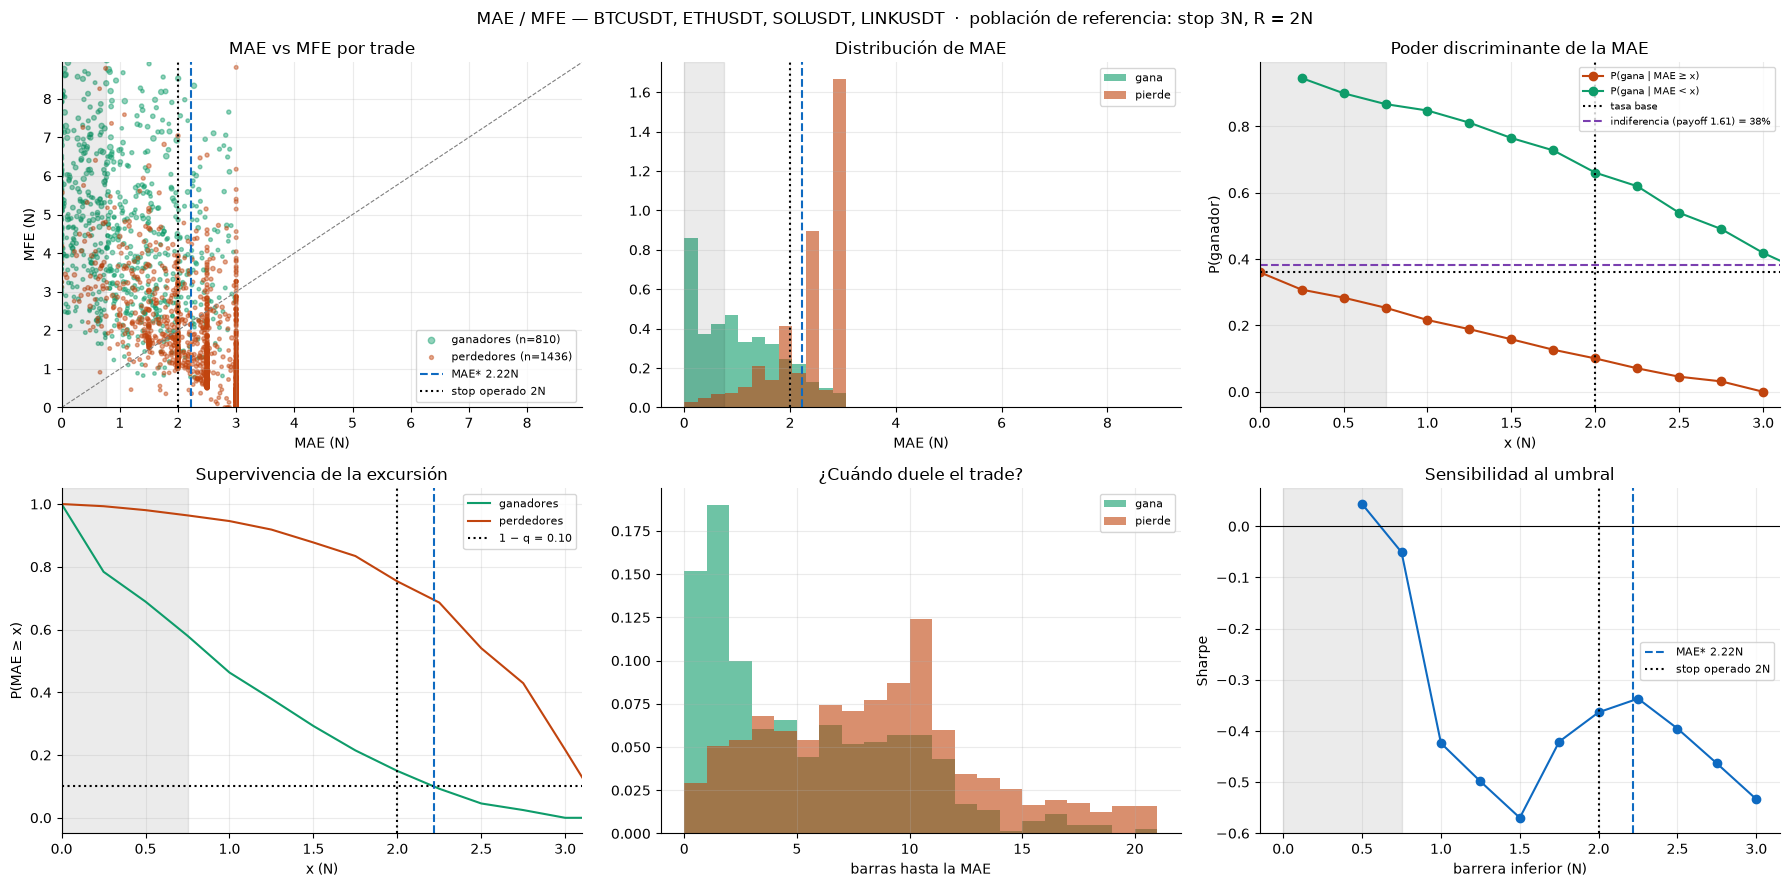

,barrera_N,barrera_R,CAGR,Sharpe,Max DD,trades,win,R media,resoluble
0,0.500000,0.25,+1.2%,0.04,-58.4%,3151,11%,-0.010,False
1,0.750000,0.38,-1.6%,-0.05,-67.9%,3034,11%,-0.016,False
2,1.000000,0.50,-13.4%,-0.42,-74.0%,2919,12%,-0.061,True
3,1.250000,0.62,-16.3%,-0.50,-78.5%,2798,15%,-0.091,True
4,1.500000,0.75,-18.2%,-0.57,-78.0%,2677,19%,-0.104,True
5,1.750000,0.88,-14.0%,-0.42,-77.8%,2564,23%,-0.088,True
6,2.000000,1.00,-13.2%,-0.36,-77.8%,2486,26%,-0.072,True
7,2.250000,1.12,-12.8%,-0.34,-74.9%,2409,29%,-0.049,True
8,2.500000,1.25,-14.4%,-0.40,-77.5%,2346,32%,-0.076,True
9,2.750000,1.38,-16.7%,-0.46,-80.9%,2296,34%,-0.115,True


In [23]:
# ── Los seis paneles del análisis MAE ──────────────────────────────────────
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
_rabs = TR_OBS.r_multiple.abs()

# (1) MAE vs MFE. La diagonal es E-ratio = 1. El tamaño es |R|, no USDT: con
#     interés compuesto el P&L en dinero pesaría más los trades tardíos.
for w, c, lab in [(True, "#0e9c6a", "ganadores"), (False, "#c1440e", "perdedores")]:
    d = TR_OBS[TR_OBS.win == w]
    ax[0, 0].scatter(d.mae_n, d.mfe_n, s=6 + 30 * d.r_multiple.abs() / max(_rabs.max(), 1e-9),
                     c=c, alpha=.45, label=f"{lab} (n={len(d)})")
_lim = float(np.nanpercentile(np.r_[TR_OBS.mae_n, TR_OBS.mfe_n], 98))
ax[0, 0].plot([0, _lim], [0, _lim], lw=.8, c="gray", ls="--")
ax[0, 0].axvspan(0, FLOOR_N, color="k", alpha=.08)
ax[0, 0].axvline(MAE_STAR, ls="--", c="#0e6ac1", label=f"MAE* {MAE_STAR:.2f}N")
ax[0, 0].axvline(STOP_N, ls=":", c="k", label=f"stop operado {STOP_N:.0f}N")
ax[0, 0].set(xlabel="MAE (N)", ylabel="MFE (N)", xlim=(0, _lim), ylim=(0, _lim),
             title="MAE vs MFE por trade")
ax[0, 0].legend(fontsize=8)

# (2) Distribuciones de MAE. La zona sombreada es irresoluble.
bins = np.linspace(0, max(CALIB_STOP_N, _lim), 36)
ax[0, 1].hist(W.mae_n, bins=bins, alpha=.6, density=True, color="#0e9c6a", label="gana")
ax[0, 1].hist(L.mae_n, bins=bins, alpha=.6, density=True, color="#c1440e", label="pierde")
ax[0, 1].axvspan(0, FLOOR_N, color="k", alpha=.08)
ax[0, 1].axvline(MAE_STAR, ls="--", c="#0e6ac1"); ax[0, 1].axvline(STOP_N, ls=":", c="k")
ax[0, 1].set(xlabel="MAE (N)", title="Distribución de MAE"); ax[0, 1].legend(fontsize=8)

# (3) LA PUERTA, con la curva de indiferencia en probabilidad: el acierto
#     mínimo que hace falta con el payoff de esta población. Donde
#     P(gana | MAE ≥ x) cae por debajo, un trade que ya ha ido x en contra
#     tiene, en promedio, esperanza negativa si se mantiene.
_pay = W.r_multiple.mean() / abs(L.r_multiple.mean())
P_BREAKEVEN = 1.0 / (1.0 + _pay)
ax[0, 2].plot(CUR.x_n, CUR.p_win_ge, "o-", color="#c1440e", label="P(gana | MAE ≥ x)")
ax[0, 2].plot(CUR.x_n, CUR.p_win_lt, "o-", color="#0e9c6a", label="P(gana | MAE < x)")
ax[0, 2].axhline(TR_OBS.win.mean(), ls=":", c="k", label="tasa base")
ax[0, 2].axhline(P_BREAKEVEN, ls="--", c="#7a3fb0",
                 label=f"indiferencia (payoff {_pay:.2f}) = {P_BREAKEVEN:.0%}")
ax[0, 2].axvspan(0, FLOOR_N, color="k", alpha=.08)
ax[0, 2].axvline(STOP_N, ls=":", c="k")
ax[0, 2].set(xlabel="x (N)", ylabel="P(ganador)", title="Poder discriminante de la MAE",
             xlim=(0, CALIB_STOP_N + 0.1))
ax[0, 2].legend(fontsize=7)

# (4) Supervivencia: MAE* al cuantil q es donde surv_win = 1 − q.
ax[1, 0].plot(CUR.x_n, CUR.surv_win, color="#0e9c6a", label="ganadores")
ax[1, 0].plot(CUR.x_n, CUR.surv_loss, color="#c1440e", label="perdedores")
ax[1, 0].axhline(0.10, ls=":", c="k", label="1 − q = 0.10")
ax[1, 0].axvline(MAE_STAR, ls="--", c="#0e6ac1"); ax[1, 0].axvline(STOP_N, ls=":", c="k")
ax[1, 0].axvspan(0, FLOOR_N, color="k", alpha=.08)
ax[1, 0].set(xlabel="x (N)", ylabel="P(MAE ≥ x)", title="Supervivencia de la excursión",
             xlim=(0, CALIB_STOP_N + 0.1))
ax[1, 0].legend(fontsize=8)

# (5) Cuándo ocurre la MAE dentro del trade.
_bins = range(0, BASELINE.max_hold_bars + 2)
ax[1, 1].hist(W.bars_to_mae, bins=_bins, alpha=.6, density=True, color="#0e9c6a", label="gana")
ax[1, 1].hist(L.bars_to_mae, bins=_bins, alpha=.6, density=True, color="#c1440e", label="pierde")
ax[1, 1].set(xlabel="barras hasta la MAE", title="¿Cuándo duele el trade?")
ax[1, 1].legend(fontsize=8)

# (6) Sensibilidad: la barrera inferior recorre toda la banda, con R = 2N fija.
#     Se corre la CARTERA (una cuenta, topes compartidos), como en §8.
SENS_GRID = np.round(np.arange(0.5, 3.01, 0.25), 2)
_rows = []
for _b in SENS_GRID:
    _p = BacktestParams(**{**PORT_P.__dict__, "mae_stop_n": float(_b)})
    _ec, _tr, _ = run_portfolio_backtest(DATA_C, _p, funding=FUNDING,
                                         corr_groups=CORR_GROUPS, policy=POLICY,
                                         paths=PATHS)
    _m = equity_metrics(_ec, _tr, freq=FREQ)
    _rows.append({"barrera_N": _b, "barrera_R": _b / STOP_N,
                  "CAGR": _m.get("CAGR", np.nan), "Sharpe": _m.get("Sharpe", np.nan),
                  "Max DD": _m.get("Max DD", np.nan), "trades": len(_tr),
                  "win": _m.get("Win rate", np.nan),
                  "R media": _tr.r_multiple.mean(),
                  "resoluble": _b >= FLOOR_N})
SENS = pd.DataFrame(_rows)
ax[1, 2].plot(SENS.barrera_N, SENS.Sharpe, "o-", color="#0e6ac1")
ax[1, 2].axvspan(0, FLOOR_N, color="k", alpha=.08)
ax[1, 2].axvline(MAE_STAR, ls="--", c="#0e6ac1", label=f"MAE* {MAE_STAR:.2f}N")
ax[1, 2].axvline(STOP_N, ls=":", c="k", label=f"stop operado {STOP_N:.0f}N")
ax[1, 2].axhline(0, lw=.8, c="k")
ax[1, 2].set(xlabel="barrera inferior (N)", ylabel="Sharpe", title="Sensibilidad al umbral")
ax[1, 2].legend(fontsize=8)
plt.suptitle(f"MAE / MFE — {', '.join(CRYPTO)}  ·  población de referencia: {_KEY}, R = {STOP_N:.0f}N")
plt.tight_layout(); plt.show()

display(SENS.style.format({"barrera_R": "{:.2f}", "CAGR": "{:+.1%}", "Sharpe": "{:.2f}",
                           "Max DD": "{:.1%}", "win": "{:.0%}", "R media": "{:+.3f}"})
        .background_gradient(subset=["Sharpe"], cmap="RdYlGn"))


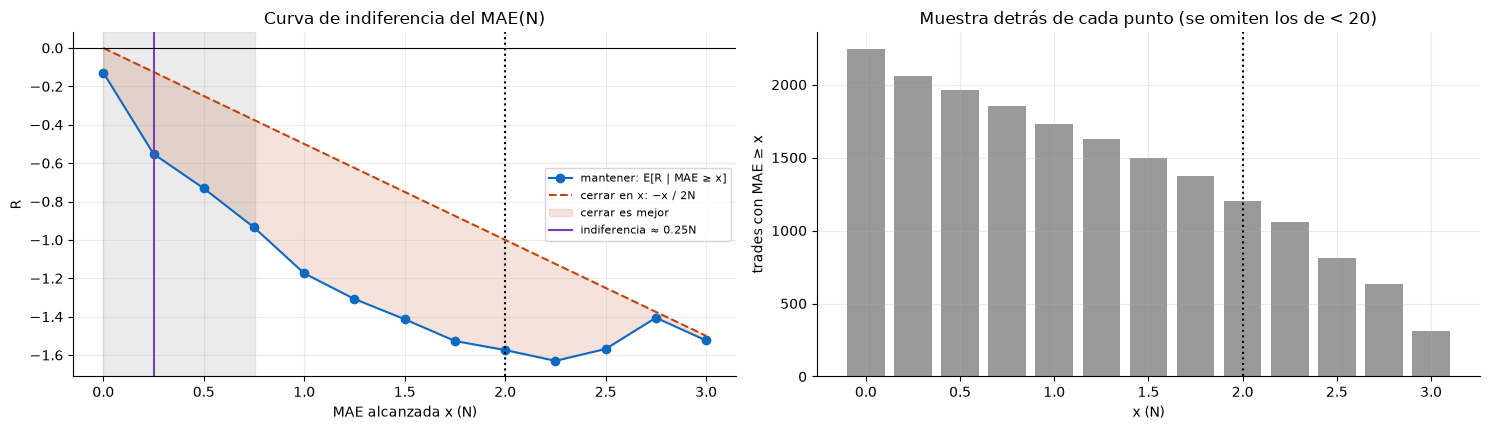

In [24]:
# ── Curva de indiferencia en valor: mantener frente a cerrar ────────────────
# En el instante en que un trade toca MAE = x, cerrar vale aproximadamente
# −x/STOP_N R (más costes). Mantener vale, en promedio, E[R | MAE ≥ x]: el
# desenlace de los trades que llegaron a ese punto. Donde la segunda curva
# cae por debajo de la primera, cortar en x es mejor que esperar; ese cruce es
# el punto de indiferencia del MAE, y es la forma rigurosa del panel (3).
_x = GRID_X[GRID_X <= CALIB_STOP_N]
_hold = np.array([TR_OBS.loc[TR_OBS.mae_n >= x, "r_multiple"].mean()
                  if (TR_OBS.mae_n >= x).sum() >= 20 else np.nan for x in _x])
_n = np.array([(TR_OBS.mae_n >= x).sum() for x in _x])
_cut = -_x / STOP_N
_diff = _hold - _cut
# El cruce se busca en x > 0: en x = 0 "cerrar" equivale a no operar, y si el
# sistema entero tiene esperanza negativa ese punto ya sale por debajo, lo que
# no es un umbral sino un veredicto sobre la señal (se imprime aparte).
E_ALL = float(TR_OBS.r_multiple.mean())
X_IND = next((float(x) for x, d in zip(_x, _diff) if x > 0 and np.isfinite(d) and d < 0),
             np.nan)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
ax[0].plot(_x, _hold, "o-", color="#0e6ac1", label="mantener: E[R | MAE ≥ x]")
ax[0].plot(_x, _cut, "--", color="#c1440e", label="cerrar en x: −x / 2N")
ax[0].fill_between(_x, _hold, _cut, where=np.isfinite(_diff) & (_diff < 0),
                   color="#c1440e", alpha=.15, label="cerrar es mejor")
ax[0].axvspan(0, FLOOR_N, color="k", alpha=.08)
ax[0].axvline(STOP_N, ls=":", c="k")
if np.isfinite(X_IND):
    ax[0].axvline(X_IND, color="#7a3fb0", lw=1.5, label=f"indiferencia ≈ {X_IND:.2f}N")
ax[0].axhline(0, lw=.8, c="k")
ax[0].set(xlabel="MAE alcanzada x (N)", ylabel="R", title="Curva de indiferencia del MAE(N)")
ax[0].legend(fontsize=8)

ax[1].bar(_x, _n, width=0.2, color="0.6")
ax[1].axvline(STOP_N, ls=":", c="k")
ax[1].set(xlabel="x (N)", ylabel="trades con MAE ≥ x",
          title="Muestra detrás de cada punto (se omiten los de < 20)")
plt.tight_layout(); plt.show()


In [25]:
# ── Veredicto del análisis MAE ─────────────────────────────────────────────
print("=" * 78); print("  ¿DISCRIMINA LA MAE?"); print("=" * 78)
_base = TR_OBS.win.mean()
_res = CUR[(CUR.x_n >= FLOOR_N) & (CUR.x_n <= CALIB_STOP_N)]
_lift = float(_res.lift.mean())
_mono = bool((_res.p_win_ge.diff().dropna() <= 1e-9).mean() > 0.75)
_pge = float(CUR.loc[(CUR.x_n - MAE_STAR).abs().idxmin(), "p_win_ge"])

print(f"\n  Población de calibración       : barrera {CALIB_STOP_N:.0f}N, R = {STOP_N:.0f}N")
print(f"  Trades / ganadores             : {len(TR_OBS)} / {len(W)}  (tasa base {_base:.1%})")
print(f"  P(gana | MAE ≥ MAE*)           : {_pge:.1%}")
print(f"  Acierto de indiferencia        : {P_BREAKEVEN:.1%}  (payoff {_pay:.2f})")
print(f"  Lift medio en la zona resoluble: {_lift:+.3f}   (negativo = la MAE informa)")
print(f"  Monótona decreciente           : {'sí' if _mono else 'NO'}")
print(f"  Separación KS                  : {float(CUR.ks.max()):.2f}")
print(f"  E-ratio (MFE/MAE)              : {edge_ratio(TR_OBS.mfe_n, TR_OBS.mae_n):.2f}")
MAE_DISCRIMINA = _lift < -0.05 and _mono
print("\n  " + ("✓ La MAE SÍ discrimina: la probabilidad de acabar en ganancia cae de forma\n"
                "    monótona con la excursión adversa." if MAE_DISCRIMINA else
                "✗ La MAE NO discrimina de forma útil: cualquier umbral solo añadiría coste."))

print("\n" + "=" * 78); print("  ¿HAY SITIO PARA UN CIERRE TEMPRANO DENTRO DEL STOP DE 2N?"); print("=" * 78)
print(f"\n  Suelo de resolución  : {FLOOR_N:.2f} N = {FLOOR_N/STOP_N:.2f} R")
print(f"  MAE* calibrado       : {MAE_STAR:.2f} N = {MAE_STAR/STOP_N:.2f} R")
print(f"  MAE p90 de ganadores : {W.mae_n.quantile(.90):.2f} N")
print(f"  Indiferencia en valor: " + (f"{X_IND:.2f} N = {X_IND/STOP_N:.2f} R" if np.isfinite(X_IND)
                                      else "no hay cruce dentro de la banda"))
CABE = FLOOR_N <= MAE_STAR < STOP_N
# "Cabe" con un margen de un 5 % al stop no es un umbral: es el propio stop.
DEGENERADO = CABE and MAE_STAR >= 0.95 * STOP_N
print(f"\n  MAE* dentro de [suelo, stop): {'✓ CABE' if CABE else '✗ NO CABE'}"
      + ("  — pero pegado al stop: DEGENERADO" if DEGENERADO else ""))
if CABE and not DEGENERADO:
    print(f"     Banda resoluble para el cierre temprano: [{FLOOR_N/STOP_N:.2f} R, 1.00 R)"
          f"  ->  umbral en {MAE_STAR/STOP_N:.2f} R")
if DEGENERADO:
    print("     El 90 % de los ganadores cabe justo hasta el stop: un cierre por MAE*")
    print("     no añade nada al stop que ya se opera. MAE* protege ganadores, no mide")
    print("     si mantener a los que van en contra compensa — eso lo dice la curva de valor.")

print("\n" + "=" * 78); print("  LECTURA DE LA CURVA DE INDIFERENCIA EN VALOR"); print("=" * 78)
_imm = TR_OBS[TR_OBS.mae_n < 0.25]
print(f"\n  Trades que nunca van ≥ 0.25N en contra: {len(_imm)/len(TR_OBS):.1%} del total, "
      f"R media {_imm.r_multiple.mean():+.2f}")
print(f"  Trades que sí llegan a 0.25N en contra : R media "
      f"{TR_OBS.loc[TR_OBS.mae_n >= 0.25, 'r_multiple'].mean():+.2f}  (cortar ahí: -0.12 R)")
_below = np.isfinite(_diff) & (_diff < 0)
print(f"  Mantener es PEOR que cortar en {_below.sum()} de {np.isfinite(_diff).sum()} "
      f"puntos de la rejilla ({_x[_below].min():.2f}N … {_x[_below].max():.2f}N)"
      if _below.any() else "  Mantener es mejor que cortar en toda la rejilla.")
if np.isfinite(X_IND) and X_IND < FLOOR_N:
    print(f"\n  El cruce ({X_IND:.2f}N) cae POR DEBAJO del suelo de resolución ({FLOOR_N:.2f}N):")
    print("  no es un umbral operable a esta granularidad —dentro de una vela no se sabe")
    print("  qué llegó antes—. Lo que dice es estructural: la esperanza del sistema la")
    print("  ponen los trades que arrancan a favor y no miran atrás; los que van en")
    print("  contra, aunque sea poco, pierden en promedio más de lo que costaría soltarlos.")
    print("  Cuadra con el panel (6): cerrar antes del stop de 2N mejora el Sharpe hasta")
    print("  donde la resolución lo permite.")
if E_ALL < 0:
    print(f"\n  Ojo: la población entera tiene esperanza NEGATIVA ({E_ALL:+.3f} R). En x = 0")
    print("  'cortar' ya vale más que mantener: ningún umbral de MAE convierte en")
    print("  rentable una señal que no lo es; como mucho reduce lo que pierde.")
print("\n  Coste no incluido en la línea de 'cortar': una ida y vuelta más por trade")
print("  cortado. Con R = 2N en estas cripto, del orden de 0.05-0.10 R.")

_eo = CALIB.set_index("régimen")["E-ratio"]
print(f"\n  E-ratio: {_eo.iloc[0]:.2f} sin stop  vs  {_eo.iloc[-1]:.2f} con el stop operado.")
print("  Un stop acota la MAE y no la MFE, así que infla el E-ratio por construcción:")
print("  el valor sin stop es el que describe la ENTRADA. "
      + ((">1: la entrada tiene ventaja direccional por sí misma.") if _eo.iloc[0] >= 1 else
         ("<1: la entrada no tiene ventaja direccional; la esperanza positiva la crea la"
          "\n  gestión (stop + escalera), no la señal." if E_ALL > 0 else
          "<1: la entrada no tiene ventaja direccional, y la gestión tampoco la\n"
          "  compensa: la esperanza total es negativa.")))

_best = SENS.loc[SENS.Sharpe.idxmax()]
_op = SENS.loc[(SENS.barrera_N - STOP_N).abs().idxmin()]
print(f"\n  Sensibilidad (cartera): Sharpe máximo {_best.Sharpe:.2f} con barrera "
      f"{_best.barrera_N:.2f}N;  con la barrera operada ({STOP_N:.0f}N) {_op.Sharpe:.2f}.")
print("  Este barrido es búsqueda sobre la misma muestra: su mejor punto no es un\n"
      "  umbral a adoptar, es un techo optimista. Lo que se lee es la FORMA de la curva.")

N_TRIALS += len(SENS_GRID)
print(f"\n+{len(SENS_GRID)} configuraciones de sensibilidad -> n_trials del DSR = {N_TRIALS}")


  ¿DISCRIMINA LA MAE?

  Población de calibración       : barrera 3N, R = 2N
  Trades / ganadores             : 2246 / 810  (tasa base 36.1%)
  P(gana | MAE ≥ MAE*)           : 7.1%
  Acierto de indiferencia        : 38.3%  (payoff 1.61)
  Lift medio en la zona resoluble: -0.549   (negativo = la MAE informa)
  Monótona decreciente           : sí
  Separación KS                  : 0.62
  E-ratio (MFE/MAE)              : 1.35

  ✓ La MAE SÍ discrimina: la probabilidad de acabar en ganancia cae de forma
    monótona con la excursión adversa.

  ¿HAY SITIO PARA UN CIERRE TEMPRANO DENTRO DEL STOP DE 2N?

  Suelo de resolución  : 0.76 N = 0.38 R
  MAE* calibrado       : 2.22 N = 1.11 R
  MAE p90 de ganadores : 2.22 N
  Indiferencia en valor: 0.25 N = 0.12 R

  MAE* dentro de [suelo, stop): ✗ NO CABE

  LECTURA DE LA CURVA DE INDIFERENCIA EN VALOR

  Trades que nunca van ≥ 0.25N en contra: 8.2% del total, R media +4.59
  Trades que sí llegan a 0.25N en contra : R media -0.55  (cortar ahí: -0.

### §8.4 Opción (a): cerrar al final de la sesión, contra (b): stops en reposo 24/7

Dos maneras coherentes de operar una señal que nace en la sesión:

| | (b) — lo que corre el resto del cuaderno | (a) — esta sección |
|---|---|---|
| Posición de noche | se mantiene; el stop queda puesto en el exchange | **no existe**: se cierra al cierre de la última barra de sesión |
| Riesgo fuera de sesión | un stop de 2N calibrado con velas de 30 min frente a 17 h y fines de semana | ninguno |
| Coste | el hueco nocturno | un round-trip forzado y trades cortados a mitad de camino |
| Barrera temporal | `max_hold_bars` = 20 barras (> 1 sesión) | una sesión (13 barras útiles) **acota por debajo** de `max_hold_bars` |

En (a) el motor (`flat_at_session_end=True`) sale con motivo `cierre_sesion` al cierre de la
última barra de cada sesión y **no abre** en esa barra: sería una posición de una sola vela
cerrada a la fuerza (el rechazo cuenta como `fin_sesion`). La última barra se reconoce por el
hueco hasta la siguiente, que es el horario: se conoce de antemano, no es look-ahead. El
camino 24/7 se sigue pasando, y lo que tiene que dar es **cero** salidas `stop_fuera`.

Se prueban los tres sistemas de §6 con (a). Son configuraciones nuevas sobre la misma muestra:
suman al `n_trials` del DSR.


In [26]:
from dataclasses import replace

FLAT_SYSTEMS = {etq: (replace(params, flat_at_session_end=True), pol)
                for etq, (params, pol) in SYSTEMS.items()}

RESULTS_A, rows_a = {}, []
for s in PILOT:
    RESULTS_A[s] = {}
    for etq, (params, pol) in FLAT_SYSTEMS.items():
        ec, tr = run_backtest(DATA[s], params, funding=FUNDING[s], policy=pol,
                              path=PATHS.get(s))
        assert not tr.reason.isin(["stop_fuera", "target_fuera"]).any(), \
            f"{s}: una posición cruzó la noche con cierre de sesión activo"
        RESULTS_A[s][etq] = (ec, tr)
        rows_a.append({**metrics_row(s, ec, tr, etq), "modo": "(a) cierre sesión"})

AB_TABLE = pd.concat([BASE_TABLE.assign(modo="(b) stops 24/7"),
                      pd.DataFrame(rows_a)], ignore_index=True)
AB_TABLE = AB_TABLE.set_index(["sistema", "símbolo", "modo"]).sort_index()
display(AB_TABLE.drop(columns=["años"]).style.format({
    "CAGR": "{:+.1%}", "Sharpe": "{:.2f}", "Max DD": "{:.1%}",
    "win rate": "{:.1%}", "profit factor": "{:.2f}", "R media": "{:+.3f}"}))

N_TRIALS += len(FLAT_SYSTEMS)
print(f"\n+{len(FLAT_SYSTEMS)} configuraciones (a) -> n_trials del DSR = {N_TRIALS}")



+3 configuraciones (a) -> n_trials del DSR = 69


In [27]:
# Dónde sale cada operación en (a), y cuánto se lleva el coste.
def _cat(frames):
    # attrs (fills, libro abierto) no se pueden comparar al concatenar.
    return pd.concat([pd.DataFrame(f.to_dict("list")) for f in frames],
                     ignore_index=True)

def cost_r(tr, p):
    # Comisiones de la operación en R de la PRIMERA unidad (el mismo
    # denominador que r_multiple). Incluye las de los adds.
    qty0 = tr["notional0"] / tr["entry0"]
    return tr["fees"] / (p.stop_n * tr["n"] * qty0)

rows = []
for etq, (params, _) in FLAT_SYSTEMS.items():
    for modo, res in (("(b) stops 24/7", RESULTS), ("(a) cierre sesión", RESULTS_A)):
        tr = _cat([res[s][etq][1] for s in PILOT if s not in LATE])
        mix = tr.reason.value_counts(normalize=True)
        rows.append({"sistema": etq, "modo": modo, "trades": len(tr),
                     "R media": tr.r_multiple.mean(),
                     "R bruta": (tr.r_multiple + cost_r(tr, params)).mean(),
                     "coste R": cost_r(tr, params).mean(),
                     "barras": tr.bars_held.mean(),
                     **{f"% {k}": mix.get(k, 0.0) for k in
                        ("stop", "stop_fuera", "target", "target_fuera",
                         "vertical", "cierre_sesion")}})
EXIT_AB = pd.DataFrame(rows).set_index(["sistema", "modo"])
print("Cripto agregadas (BTC, ETH, SOL, LINK):")
display(EXIT_AB.style.format({"R media": "{:+.3f}", "R bruta": "{:+.3f}",
                              "coste R": "{:.3f}", "barras": "{:.1f}",
                              **{c: "{:.0%}" for c in EXIT_AB.columns if c.startswith("%")}}))

# R de las salidas por cierre de sesión: ¿se corta a ganadores o a perdedores?
_cs = _cat([RESULTS_A[s][MAIN][1] for s in PILOT if s not in LATE])
_cs = _cs[_cs.reason == "cierre_sesion"]
if len(_cs):
    print(f"\nSistema principal, salidas 'cierre_sesion': {len(_cs)}  "
          f"R media {_cs.r_multiple.mean():+.3f}  positivas {(_cs.r_multiple > 0).mean():.0%}  "
          f"MFE media {_cs.mfe_n.mean():.2f}N")


Cripto agregadas (BTC, ETH, SOL, LINK):



Sistema principal, salidas 'cierre_sesion': 2096  R media +0.335  positivas 51%  MFE media 1.32N


Cartera conjunta (VWAP ≥2N, 100k, 4x bruto, DD desde el máximo):


,CAGR,Sharpe,Max DD,final,trades,suma R,R media
(b) stops 24/7,-14.5%,-0.40,-78.5%,"48,035",2547,-212.4,-0.083
(a) cierre sesión,-12.0%,-0.49,-65.3%,"54,941",2797,-142.7,-0.051


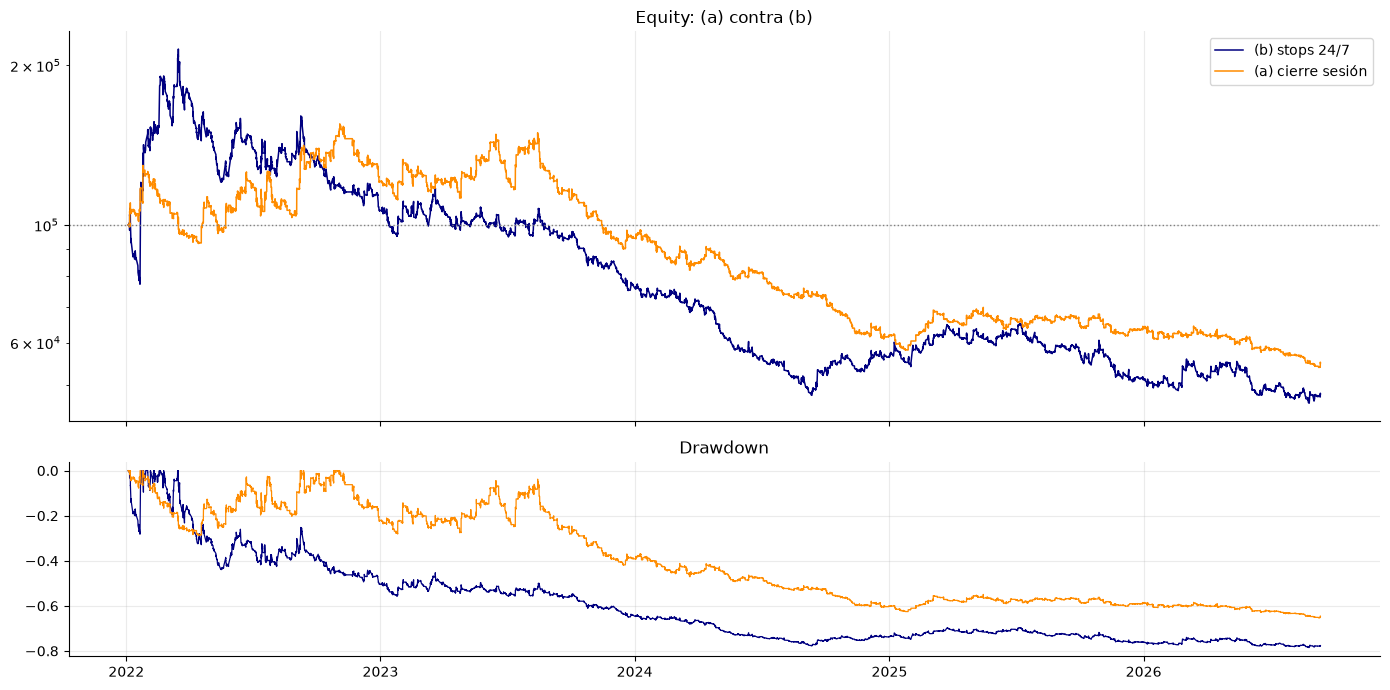

In [28]:
PORT_A = replace(PORT_P, flat_at_session_end=True)
EC_A, TR_A, FILLS_A = run_portfolio_backtest(
    DATA, PORT_A, funding=FUNDING, corr_groups=CORR_GROUPS,
    max_dir_units=12, max_corr_units=6, policy=POLICY, paths=PATHS)
assert not TR_A.reason.isin(["stop_fuera", "target_fuera"]).any()
M_A = equity_metrics(EC_A, TR_A, freq=FREQ)

PORT_AB = pd.DataFrame({
    "(b) stops 24/7": {**{k: M_P.get(k, np.nan) for k in ("CAGR", "Sharpe", "Max DD")},
                       "final": EC_P.iloc[-1], "trades": len(TR_P),
                       "suma R": TR_P.r_multiple.sum(), "R media": TR_P.r_multiple.mean()},
    "(a) cierre sesión": {**{k: M_A.get(k, np.nan) for k in ("CAGR", "Sharpe", "Max DD")},
                          "final": EC_A.iloc[-1], "trades": len(TR_A),
                          "suma R": TR_A.r_multiple.sum(), "R media": TR_A.r_multiple.mean()},
}).T
print("Cartera conjunta (VWAP ≥2N, 100k, 4x bruto, DD desde el máximo):")
display(PORT_AB.style.format({"CAGR": "{:+.1%}", "Sharpe": "{:.2f}", "Max DD": "{:.1%}",
                              "final": "{:,.0f}", "trades": "{:.0f}",
                              "suma R": "{:+.1f}", "R media": "{:+.3f}"}))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
for ec, etq, col in ((EC_P, "(b) stops 24/7", "navy"), (EC_A, "(a) cierre sesión", "darkorange")):
    axes[0].plot(ec.index, ec, lw=1.1, color=col, label=etq)
    axes[1].plot(ec.index, ec / ec.cummax() - 1, lw=0.9, color=col)
axes[0].axhline(PORT_P.equity0, color="0.5", ls=":", lw=1)
axes[0].set_yscale("log"); axes[0].legend(); axes[0].set_title("Equity: (a) contra (b)")
axes[1].set_title("Drawdown")
plt.tight_layout(); plt.show()


In [29]:
# Lectura, calculada en esta ejecución.
_crypto = [s for s in PILOT if s not in LATE]
_A = AB_TABLE.xs("(a) cierre sesión", level="modo")
_B = AB_TABLE.xs("(b) stops 24/7", level="modo")
print("Sistema por sistema, cripto (CAGR mínimo … máximo entre símbolos):")
for etq in SYSTEMS:
    a = _A.loc[etq].loc[_crypto]; b = _B.loc[etq].loc[_crypto]
    print(f"  {etq:<24} (b) {b.CAGR.min():+.0%} … {b.CAGR.max():+.0%}   "
          f"(a) {a.CAGR.min():+.0%} … {a.CAGR.max():+.0%}   "
          f"símbolos con CAGR > 0 en (a): {(a.CAGR > 0).sum()}/{len(_crypto)}")

_ea = EXIT_AB.xs("(a) cierre sesión", level="modo").loc[MAIN]
_eb = EXIT_AB.xs("(b) stops 24/7", level="modo").loc[MAIN]
print(f"\nSistema principal: R media {_eb['R media']:+.3f} -> {_ea['R media']:+.3f};  "
      f"R bruta {_eb['R bruta']:+.3f} -> {_ea['R bruta']:+.3f};  "
      f"coste {_eb['coste R']:.3f} -> {_ea['coste R']:.3f} R/op")
print(f"Cartera: CAGR {M_P['CAGR']:+.1%} -> {M_A['CAGR']:+.1%};  Sharpe "
      f"{M_P['Sharpe']:.2f} -> {M_A['Sharpe']:.2f};  MaxDD {M_P['Max DD']:.0%} -> {M_A['Max DD']:.0%}")

if _ea["R bruta"] <= 0:
    print("\n=> Sin costes la esperanza de (a) ya es <= 0: la señal no tiene edge dentro de la\n"
          "   sesión. Cerrar de noche quita el riesgo del hueco, pero no crea ventaja.")
elif _ea["R media"] <= 0:
    print("\n=> (a) tiene esperanza bruta positiva que los costes se comen: el problema\n"
          "   vuelve a ser el coste por R, no la noche.")
else:
    print("\n=> (a) tiene esperanza positiva después de costes: candidato a validar fuera\n"
          "   de muestra (WFO) antes de sacar ninguna conclusión.")


Sistema por sistema, cripto (CAGR mínimo … máximo entre símbolos):
  canal (mid)              (b) -17% … -5%   (a) -13% … -10%   símbolos con CAGR > 0 en (a): 0/4
  sin objetivo             (b) -16% … -4%   (a) -10% … +7%   símbolos con CAGR > 0 en (a): 1/4
  sin objetivo + VWAP ≥2N  (b) -7% … -4%   (a) -10% … +5%   símbolos con CAGR > 0 en (a): 1/4

Sistema principal: R media -0.066 -> -0.042;  R bruta -0.027 -> -0.008;  coste 0.038 -> 0.034 R/op
Cartera: CAGR -14.5% -> -12.0%;  Sharpe -0.40 -> -0.49;  MaxDD -78% -> -65%

=> Sin costes la esperanza de (a) ya es <= 0: la señal no tiene edge dentro de la
   sesión. Cerrar de noche quita el riesgo del hueco, pero no crea ventaja.


### Lectura de §8.4

**Cerrar al final de la sesión quita el riesgo de la noche pero no crea edge.** Las salidas
`stop_fuera` desaparecen y el drawdown de la cartera baja, pero la **R bruta** —antes de
comisiones— del sistema principal queda prácticamente en cero: dentro de la sesión la señal
no tiene ventaja que los costes puedan comerse. Con (b) la noche empeoraba un sistema que ya
era nulo; con (a) se ve el sistema nulo tal cual.

Las salidas `cierre_sesion` son el único grupo con R media positiva: la operación que no se
para dentro de la sesión suele ir a favor al cierre. Pero es la mitad de la moneda —los stops
de sesión se llevan lo mismo— y no es una ventaja explotable sin otro cambio de diseño.

Que un símbolo (LINK) salga positivo en (a) no es evidencia: 1 de 4 símbolos, en una prueba
que eleva el `n_trials` del DSR, con el resto negativos. El veredicto de §13 —calculado sobre
(b)— no cambia de sentido con (a).


## §9. Walk-Forward sobre el símbolo bandera

Folds anclados al calendario: IS = 365 d, OOS = 90 d, embargo = 2 d. Se optimiza **dentro** de
cada IS y se mide **fuera**.

QQQ queda fuera de esta sección por construcción: con 160 días de historia no cabe un solo
fold de 365 d de IS. Reportarlo como si cupiera sería inventarse la validación.

**Una sola palanca.** Siguiendo §8.2, la rejilla es **solo `max_hold_bars`**: el objetivo queda
apagado y el filtro de VWAP fijo en su valor declarado. Menos búsqueda es más potencia para el
DSR, y la pregunta queda limpia.

**Criterio de selección: Sharpe.** No la R media — §8.2 mostró que la R por operación sube casi
sin límite al alargar el horizonte mientras el riesgo ajustado empeora.

**Contraste.** El sistema seleccionado se compara con **el mismo sistema con la barrera
prefijada** (`max_hold_bars` del motor). Así el test responde exactamente a una pregunta:
*¿elegir el horizonte dentro de muestra aporta algo fuera de ella frente a no elegirlo?*


In [30]:
WFO_GRID = [{"max_hold_bars": h} for h in WFO_HOLDS]
print(f"Rejilla: {WFO_GRID}")

# Parte la configuración: unas claves son del motor, otras de la política.
def run_cfg(cfg, d, fund):
    pol_keys = {"min_range_n", "vwap_mode", "vwap_bars"}
    pk = {k: v for k, v in cfg.items() if k in pol_keys}
    pp = {k: v for k, v in cfg.items() if k not in pol_keys}
    params = BacktestParams(**{**BASELINE.__dict__, **pp})
    pol = vwap_fade_policy(min_range_n=pk.get("min_range_n", MIN_RANGE_N),
                           vwap_mode=pk.get("vwap_mode", VWAP_MODE),
                           vwap_bars=pk.get("vwap_bars", VWAP_BARS))
    return run_backtest(d, params, funding=fund, policy=pol,
                        path=PATHS.get(FLAGSHIP))

FOLDS = walk_forward_folds(df0.index, is_days=365, oos_days=90, embargo_days=2)
print(f"{len(FOLDS)} folds sobre {FLAGSHIP}")
print(f"QQQUSDT: {len(DATA['QQQUSDT'])} barras / "
      f"{(DATA['QQQUSDT'].index[-1]-DATA['QQQUSDT'].index[0]).days} días -> 0 folds posibles")


Rejilla: [{'max_hold_bars': 10}, {'max_hold_bars': 15}, {'max_hold_bars': 20}, {'max_hold_bars': 30}, {'max_hold_bars': 45}]
14 folds sobre BTCUSDT
QQQUSDT: 1610 barras / 158 días -> 0 folds posibles


In [31]:
from collections import Counter

fold_rows, oos_sel, oos_base, winners = [], [], [], []
fund0 = FUNDING[FLAGSHIP]
for f in FOLDS:
    is_df  = df0[(df0.index >= f["is_start"])  & (df0.index < f["is_end"])]
    oos_df = df0[(df0.index >= f["oos_start"]) & (df0.index < f["oos_end"])]
    if len(is_df) < 200 or len(oos_df) < 50:
        continue
    is_f  = fund0[(fund0.index >= f["is_start"])  & (fund0.index < f["is_end"])]
    oos_f = fund0[(fund0.index >= f["oos_start"]) & (fund0.index < f["oos_end"])]

    best, best_score = None, -np.inf
    for cfg in WFO_GRID:
        ec_is, _ = run_cfg(cfg, is_df, is_f)
        m = equity_metrics(ec_is, freq=FREQ)
        score = m.get("Sharpe", -np.inf)
        if score > best_score:
            best_score, best = score, cfg
    winners.append(tuple(sorted(best.items())))

    ec_s, _ = run_cfg(best, oos_df, oos_f)
    ec_b, _ = run_cfg({}, oos_df, oos_f)     # misma política, barrera prefijada
    r_s, r_b = ec_s.pct_change().dropna(), ec_b.pct_change().dropna()
    common = r_s.index.intersection(r_b.index)
    oos_sel.append(r_s.loc[common]); oos_base.append(r_b.loc[common])
    fold_rows.append({"fold": f["fold"], "oos_ini": f["oos_start"].date(),
                      "ganador": best,
                      "Sharpe_sel": equity_metrics(ec_s, freq=FREQ).get("Sharpe", np.nan),
                      "Sharpe_base": equity_metrics(ec_b, freq=FREQ).get("Sharpe", np.nan)})

FOLDS_DF = pd.DataFrame(fold_rows)
display(FOLDS_DF.style.format({"Sharpe_sel": "{:.2f}", "Sharpe_base": "{:.2f}"}))

if len(fold_rows):
    OOS_SEL_CONCAT = pd.concat(oos_sel)
    TT = fold_ttest([r["Sharpe_sel"] for r in fold_rows],
                    [r["Sharpe_base"] for r in fold_rows])
    print(f"\nt-test OOS (horizonte elegido IS vs horizonte prefijado "
          f"{BASELINE.max_hold_bars}): {TT}")
    mode_winner, mode_count = Counter(winners).most_common(1)[0]
    print(f"Ganador modal {dict(mode_winner)} en {mode_count}/{len(winners)} folds")
else:
    OOS_SEL_CONCAT = pd.Series(dtype=float)
    TT, mode_winner, mode_count = {}, {}, 0
    print("Sin folds suficientes — criterio fallido en el checklist.")


,fold,oos_ini,ganador,Sharpe_sel,Sharpe_base
0,1,2023-01-05,{'max_hold_bars': 30},-3.29,-3.13
1,2,2023-04-05,{'max_hold_bars': 30},-1.66,-1.35
2,3,2023-07-04,{'max_hold_bars': 30},-1.13,1.72
3,4,2023-10-02,{'max_hold_bars': 20},-3.13,-3.13
4,5,2023-12-31,{'max_hold_bars': 45},-1.00,-2.45
5,6,2024-03-30,{'max_hold_bars': 45},-2.15,-2.11
6,7,2024-06-28,{'max_hold_bars': 10},-2.03,-0.21
7,8,2024-09-26,{'max_hold_bars': 10},-2.29,-1.30
8,9,2024-12-25,{'max_hold_bars': 10},0.13,2.27
9,10,2025-03-25,{'max_hold_bars': 10},-0.91,-1.32



t-test OOS (horizonte elegido IS vs horizonte prefijado 20): {'n_folds': 14, 'mean_diff': -0.44497886889319627, 't': -1.3460475903447355, 'p': 0.2012914667386602, 'wins': 4, 'win_rate': 0.2857142857142857, 'veredicto': 'NO significativa: la optimización es ruido', 'aviso_muestra': 'n<20 folds: diagnóstico cualitativo, no evidencia'}
Ganador modal {'max_hold_bars': 30} en 6/14 folds


## §10. Deflated Sharpe y PBO

El Sharpe seleccionado se compara con **lo que cabría esperar del mejor de esta rejilla sin
ningún edge**. Si no lo supera, el resultado es selección, no señal. `n_trials` es el número
real de configuraciones probadas en §7.


In [32]:
trial_sharpes, grid_returns = [], {}
for mode, bars in SWEEP_MODES:
    for thr in SWEEP_THRESHOLDS:
        pol = vwap_fade_policy(min_range_n=thr, vwap_mode=mode, vwap_bars=bars or VWAP_BARS)
        ec, _ = run_backtest(df0, BASELINE, funding=fund0, policy=pol,
                             path=PATHS.get(FLAGSHIP))
        trial_sharpes.append(equity_metrics(ec, freq=FREQ).get("Sharpe", 0.0))
        grid_returns[f"{mode}{bars or ''}_{thr}"] = ec.pct_change().dropna()

if len(OOS_SEL_CONCAT) > 10:
    DSR = deflated_sharpe_ratio(OOS_SEL_CONCAT, n_trials=N_TRIALS,
                                trial_sharpes=np.array(trial_sharpes), freq=FREQ)
    print("DSR (retornos OOS concatenados del walk-forward):")
    for k, v in DSR.items():
        print(f"  {k:<14}: {v}")
else:
    DSR = None
    print("Datos OOS insuficientes para DSR.")

PERF = pd.DataFrame(grid_returns).dropna(how="all")
try:
    PBO = pbo_cscv(PERF, n_partitions=10, freq=FREQ)
    print(f"\nPBO (CSCV): pbo={PBO['pbo']:.3f} -> {PBO['veredicto']}")
except Exception as exc:
    PBO = {"error": str(exc)}
    print(f"\nPBO no se pudo calcular: {exc}")


DSR (retornos OOS concatenados del walk-forward):
  sharpe        : -1.8135313639452777
  sr_benchmark  : 1.0945124660404266
  dsr           : 7.748825685018261e-08
  n_trials      : 69
  veredicto     : NO distinguible de ruido



PBO (CSCV): pbo=0.282 -> selección con valor


## §11. Cuantificación de sesgos


In [33]:
base_trades = RESULTS[FLAGSHIP][MAIN][1]
CONC = pnl_concentration(base_trades) if len(base_trades) else None
if CONC:
    print(f"Concentración de P&L: top_3={CONC.get('top_3', np.nan):.1%} "
          f"top_5={CONC.get('top_5', np.nan):.1%} -> {CONC.get('veredicto')}")

# Apuestas efectivas: QQQ solo solapa 160 días con el resto, así que se mide
# sobre la ventana común (si se midiera sobre la unión, las correlaciones
# cripto-QQQ saldrían de una muestra distinta que las cripto-cripto).
common_idx = DATA[PILOT[0]].index
for s in PILOT[1:]:
    common_idx = common_idx.intersection(DATA[s].index)
try:
    EB = effective_bets({s: DATA[s].loc[common_idx] for s in PILOT})
    print(f"\nApuestas efectivas (ventana común, {len(common_idx)} barras desde "
          f"{common_idx[0].date()}): n_efectivo={EB.get('n_efectivo', np.nan):.2f}  "
          f"corr_media={EB.get('corr_media', np.nan):.2f}")
    print(f"  {EB.get('veredicto')}")
except Exception as exc:
    EB = {}
    print(f"\nApuestas efectivas no calculables: {exc}")


Concentración de P&L: top_3=-355.8% top_5=-494.4% -> concentración aceptable

Apuestas efectivas (ventana común, 1610 barras desde 2026-04-06): n_efectivo=1.64  corr_media=0.70
  crees tener 5 mercados; tienes ~2


In [34]:
def run_fn(fee, slip, funding_daily):
    p = BacktestParams(**{**BASELINE.__dict__, "fee_bps": fee, "slip_bps": slip})
    synth = pd.Series(funding_daily / 3.0, index=fund0.index)
    return run_backtest(df0, p, funding=synth, policy=POLICY,
                        path=PATHS.get(FLAGSHIP))

CS = cost_sensitivity(run_fn)
display(CS.style.format({"CAGR": "{:+.1%}", "Sharpe": "{:.2f}", "MaxDD": "{:.1%}"}))
print(f"\n  Fricción CAGR (sin costes -> base): {CS.attrs.get('friccion_cagr', np.nan):+.1%}")
print(f"  Sobrevive escenario pesimista     : {CS.attrs.get('sobrevive_pesimista')}")
if not CS.attrs.get("sobrevive_pesimista") and \
        CS.loc[CS.escenario == "Sin costes", "CAGR"].iloc[0] < 0:
    print("\n  ⚠ Pierde dinero incluso SIN costes: el problema es de EDGE, no de fricción.")


,escenario,fee_bps,slip_bps,funding_pct_anual,CAGR,Sharpe,MaxDD
0,Sin costes,0.000000,0.000000,0.000000,-0.5%,-0.08,-54.1%
1,Optimista,2.000000,5.000000,3.700000,-7.0%,-1.10,-63.1%
2,Base,5.000000,10.000000,10.900000,-12.4%,-2.05,-69.1%
3,Pesimista,5.000000,25.000000,18.200000,-22.8%,-4.68,-76.0%
4,Estrés,10.000000,50.000000,36.500000,-39.3%,-9.26,-91.5%



  Fricción CAGR (sin costes -> base): +11.8%
  Sobrevive escenario pesimista     : False

  ⚠ Pierde dinero incluso SIN costes: el problema es de EDGE, no de fricción.


In [35]:
if len(base_trades) >= 10:
    MC = mc_bootstrap_trades(base_trades, equity0=BASELINE.equity0)
    print(f"Monte Carlo ({len(base_trades)} trades del bandera):")
    print(f"  p_perdida={MC['p_perdida']:.1%}   p_ruina(DD≥50%)={MC['p_ruina']:.1%}")
    print(f"  equity final p5={MC['percentiles_equity']['p5']:,.0f}  "
          f"p50={MC['percentiles_equity']['p50']:,.0f}  "
          f"p95={MC['percentiles_equity']['p95']:,.0f}")
else:
    MC = None
    print(f"Solo {len(base_trades)} trades — muestra insuficiente para Monte Carlo.")

print("\nSupervivencia / longitud de muestra:")
for s in PILOT:
    a = (DATA[s].index[-1] - DATA[s].index[0]).days / 365.25
    print(f"  {s:<10} desde {DATA[s].index[0].date()}  ({a:.2f} años)"
          f"{'   ← sonda, muestra corta' if a < 2 else ''}")


Monte Carlo (642 trades del bandera):
  p_perdida=61.9%   p_ruina(DD≥50%)=60.2%
  equity final p5=-1,225  p50=8,198  p95=18,163

Supervivencia / longitud de muestra:
  BTCUSDT    desde 2022-01-03  (4.69 años)
  ETHUSDT    desde 2022-01-03  (4.69 años)
  SOLUSDT    desde 2022-01-03  (4.69 años)
  LINKUSDT   desde 2022-01-03  (4.69 años)
  QQQUSDT    desde 2026-04-06  (0.43 años)   ← sonda, muestra corta


## §12. Libro abierto al final de la simulación

Sin esto no se sabe qué tiene puesto el sistema ahora mismo. Una curva de equity que termina
arriba con una posición perdedora abierta y sin cerrar está contando media verdad.


In [36]:
OPEN_BOOK = TR_P.attrs.get("open_book", {})
vivos = {s: ob for s, ob in OPEN_BOOK.items() if ob is not None}
if not vivos:
    print("Sin posiciones abiertas al final de la muestra en ningún símbolo.")
for s, ob in vivos.items():
    print(f"\n{s}:")
    for k, v in ob.items():
        print(f"    {k:<16}: {v}")



BTCUSDT:
    side            : -1
    qty             : 0.1033606703659053
    entry           : 78749.92422
    opened          : 2026-09-11 15:00:00
    n               : 480.5572093489679
    stop            : 79711.03863869794
    take            : 54722.06375255161
    mid             : 78239.76700936396
    units           : 1
    last_fill       : 78749.92422
    bars            : 10
    entry_fee       : 1.6279289917286885
    funding_paid    : 0.2883176375335614
    slip_paid       : 0.8140459004546091
    qty0            : 0.1033606703659053
    entry0          : 78749.92422
    mae_px          : 78793.8
    mfe_px          : 76837.8
    bars_to_mae     : 1
    bars_to_mfe     : 6
    flat_bars       : 0
    mark_price      : 77354.7
    unrealized_pnl  : 144.2113106899477

ETHUSDT:
    side            : -1
    qty             : 3.891161430357384
    entry           : 2584.9810000582916
    opened          : 2026-09-11 15:00:00
    n               : 25.527552381972264
    st

## §13. Checklist de validez — veredicto


In [37]:
CHECK = {}
CHECK["muestra_flagship_ge_2y"] = (df0.index[-1]-df0.index[0]).days/365.25 >= 2
CHECK["todos_los_simbolos_ge_2y"] = all(
    (DATA[s].index[-1]-DATA[s].index[0]).days/365.25 >= 2 for s in PILOT)
CHECK["folds_oos_ge_6"] = len(fold_rows) >= 6
CHECK["wfo_beats_baseline_60pct"] = (TT.get("win_rate", 0) > 0.6) if fold_rows else False
CHECK["wfo_diff_significant_p05"] = (TT.get("p", 1.0) < 0.05) if fold_rows else False
CHECK["params_stable_gt50pct"] = (mode_count / max(1, len(winners)) > 0.5) if fold_rows else False
CHECK["dsr_gt_0_at_95"] = bool(DSR and DSR.get("dsr", 0) > 0.95)
CHECK["pbo_lt_0.5"] = bool(PBO.get("pbo", 1.0) < 0.5) if "pbo" in PBO else False
CHECK["survives_pessimistic_costs"] = bool(CS.attrs.get("sobrevive_pesimista", False))
# Con P&L total negativo el "% del P&L" de los mejores trades no significa nada.
CHECK["top3_trades_lt_50pct"] = bool(CONC and base_trades["pnl"].sum() > 0
                                     and CONC.get("top_3", 1.0) < 0.5)
CHECK["mc_ruin_prob_lt_20pct"] = bool(MC and MC.get("p_ruina", 1.0) < 0.20)
CHECK["lookahead_tests_pass"] = LOOKAHEAD_OK
CHECK["ragged_start_respetado"] = bool(RAGGED_OK)

n_pass = sum(CHECK.values())
for k, v in CHECK.items():
    print(f"  [{'x' if v else ' '}] {k}")
print(f"\n  {n_pass}/{len(CHECK)} criterios superados.")
VERDICT = ("Condicionalmente viable — revisar criterios fallidos antes de asignar capital"
           if n_pass >= len(CHECK) * 0.7 else "NO DESPLEGAR CAPITAL con esta evidencia")
print(f"  VEREDICTO: {VERDICT}")


  [x] muestra_flagship_ge_2y
  [ ] todos_los_simbolos_ge_2y
  [x] folds_oos_ge_6
  [ ] wfo_beats_baseline_60pct
  [ ] wfo_diff_significant_p05
  [ ] params_stable_gt50pct
  [ ] dsr_gt_0_at_95
  [x] pbo_lt_0.5
  [ ] survives_pessimistic_costs
  [ ] top3_trades_lt_50pct
  [ ] mc_ruin_prob_lt_20pct
  [x] lookahead_tests_pass
  [x] ragged_start_respetado

  5/13 criterios superados.
  VEREDICTO: NO DESPLEGAR CAPITAL con esta evidencia


In [38]:
# Los números de la conclusión, de ESTA ejecución.
_cr = [s for s in PILOT if s not in LATE]
_T = BASE_TABLE.set_index(["símbolo", "sistema"])
_c = _T.loc[[(s, MAIN) for s in _cr]]
print("Sistema principal (" + MAIN + "), cripto:")
print(f"  CAGR   {_c.CAGR.min():+.0%} … {_c.CAGR.max():+.0%}")
print(f"  Sharpe {_c.Sharpe.min():.2f} … {_c.Sharpe.max():.2f}")
print(f"  Cartera conjunta: CAGR {M_P.get('CAGR', np.nan):+.0%}, Sharpe {M_P.get('Sharpe', np.nan):.2f}, "
      f"Max DD {M_P.get('Max DD', np.nan):.0%}")
print("\nValidación:")
print(f"  DSR                 : {DSR.get('dsr', np.nan) if DSR else float('nan'):.3f}  "
      f"(n_trials = {N_TRIALS})")
print(f"  WFO max_hold_bars   : p = {TT.get('p', np.nan):.2f}, gana {TT.get('wins', 0)}/"
      f"{TT.get('n_folds', 0)} folds; ganador modal {dict(mode_winner)} en "
      f"{mode_count}/{len(winners)}")
print(f"  Monte Carlo bandera : p_pérdida {MC['p_perdida']:.0%}, p(DD ≥ 50 %) {MC['p_ruina']:.0%}"
      if MC else "  Monte Carlo: sin muestra")
_pnl_flag = float(base_trades["pnl"].sum()) if len(base_trades) else 0.0
print(f"  Concentración       : top 3 = {CONC.get('top_3', np.nan):.0%} del P&L del bandera"
      if CONC and _pnl_flag > 0 else
      f"  Concentración       : no aplica (P&L total del bandera {_pnl_flag:+,.0f})")
print("\nMAE (§8.3):")
print(f"  ¿Discrimina?        : {'sí' if MAE_DISCRIMINA else 'no'}")
print(f"  MAE*                : {MAE_STAR:.2f} N = {MAE_STAR/STOP_N:.2f} R  "
      f"({'cabe' if CABE else 'NO cabe'} dentro del stop de {STOP_N:.0f}N)")
print(f"  Indiferencia (valor): " + (f"{X_IND:.2f} N = {X_IND/STOP_N:.2f} R"
                                     if np.isfinite(X_IND) else "sin cruce en la banda"))


Sistema principal (sin objetivo + VWAP ≥2N), cripto:
  CAGR   -7% … -4%
  Sharpe -0.34 … -0.19
  Cartera conjunta: CAGR -14%, Sharpe -0.40, Max DD -78%

Validación:
  DSR                 : 0.000  (n_trials = 69)
  WFO max_hold_bars   : p = 0.20, gana 4/14 folds; ganador modal {'max_hold_bars': 30} en 6/14
  Monte Carlo bandera : p_pérdida 62%, p(DD ≥ 50 %) 60%
  Concentración       : no aplica (P&L total del bandera -1,735)

MAE (§8.3):
  ¿Discrimina?        : sí
  MAE*                : 2.22 N = 1.11 R  (NO cabe dentro del stop de 2N)
  Indiferencia (valor): 0.25 N = 0.12 R


### Conclusión

**El sistema no tiene edge, y el que parecía tener era un error de simulación.** La celda de
arriba imprime los números: con las órdenes de salida evaluadas también de noche, las cripto
pierden entre el 4 y el 7 % anual y la cartera conjunta pierde. La curva que llevaba 100k a
5,7M salía de mantener posiciones abiertas de noche sin comprobar si el stop se tocaba fuera de
la sesión. No era apalancamiento —el tope de 4x funcionaba— ni interés compuesto: era una
fuente de R que no existe.

**Cómo se llegó aquí, porque es la lección reutilizable.** Filtrar una serie a una sesión es
correcto para las SEÑALES e incorrecto para el RIESGO de un activo que no cierra. Cualquier
backtest que filtre barras y mantenga posiciones a través del hueco tiene que simular las
órdenes en reposo sobre el camino completo, o su resultado es una cota superior sin valor.

Lo que queda establecido:

* **El motor modela ahora órdenes en reposo 24/7** (`path` / `paths`) y la regla de drawdown
  desde el máximo (`dd_from_peak`); ambos con tests y sin cambiar nada cuando están apagados.
* **La MAE sigue discriminando** (§8.3), pero MAE\* cae **fuera** del stop de 2N: el stop corta
  ganadores. Y con una esperanza total negativa, ningún umbral de cierre hace rentable la señal.
* **La sesión sigue siendo mucho mejor que 24/7** para esta señal (de −99 % a pérdidas de un
  dígito), pero no la vuelve positiva.
* **El diseño de salida es el problema abierto.** Un stop de 2N medido en velas de 30 minutos
  no está pensado para sobrevivir a una noche. O el sistema cierra al final de la sesión
  —opción (a), aún sin probar—, o el stop se dimensiona con la volatilidad del hueco.

Lo siguiente, por orden de valor:

1. **Probar la opción (a): cerrar todo al final de la sesión.** Es la variante coherente con
   una señal de sesión, y la única que no depende de lo que pase de noche.
2. **Si se mantienen posiciones de noche, dimensionar el stop con la volatilidad 24/7** (o del
   hueco), no con la de las velas de sesión.

### Cómo leer este veredicto

Dos cosas que ningún número de arriba dice por sí solo:

1. **QQQ no está validado, está sondeado.** Menos de medio año, cero folds de walk-forward. Su fila en
   §6 sirve para ver si la regla *se comporta* sobre un subyacente que no es cripto, no para
   decidir nada. `todos_los_simbolos_ge_2y` falla por su culpa y debe seguir fallando hasta que
   acumule muestra.
2. **El filtro se eligió, el umbral se barrió.** Que 2N sea la decisión previa y §7 muestre la
   tendencia completa es lo que separa esto de elegir el pico de una rejilla. Un filtro que hace
   algo produce una tendencia al endurecerlo; un pico aislado en 2,0 habría que leerlo como
   ruido.
3. **La sesión regular no se eligió aquí.** Sale de la medición del cuaderno anterior y de la
   descomposición de coste por R, no de probar las dos y quedarse con la buena. Pero conviene
   ser explícito: aplicada a BTC o SOL, "sesión bursátil de Nueva York" es una restricción
   prestada de otro mercado. Que funcione no prueba que exista una razón; prueba que las barras
   de madrugada y fin de semana, con su rango pequeño, envenenan N y el canal.

La comparación honesta no es "¿gana dinero?" sino **§6 —los tres sistemas sobre las mismas
barras—** y **§9 fuera de muestra**. Todo lo demás es contexto.
